# Speed Dating : pourquoi certaines personnes obtiennent-elles un second rendez-vous ?

*Certification RNCP35288 (Concepteur Développeur en Science des Données), bloc 2 : analyse
exploratoire, descriptive et inférentielle. Projet « Tinder ».*

**Contexte** : l'équipe marketing de Tinder constate une baisse des matchs. Elle dispose des
données d'expériences de *speed dating* menées de 2002 à 2004 auprès d'étudiants d'une
université américaine : rendez-vous de quatre minutes, après lesquels chacun dit s'il veut
revoir la personne et la note sur six critères (attirance, sincérité, intelligence, fun,
ambition, goûts partagés). Chaque ligne est une **décision** : celle d'un participant sur un
partenaire. Chaque rendez-vous apparaît donc **deux fois**, une ligne de chaque côté : les
8 378 lignes décrivent 4 184 rendez-vous vus des deux côtés (plus 10 lignes sans partenaire
identifié). Un même participant a eu de 5 à 22 rendez-vous. Cette structure commande le choix
de l'unité d'analyse dans tous les tests (section 5).

**Question centrale** : pourquoi certaines personnes obtiennent-elles un second rendez-vous, et
d'autres non ?
Le « second rendez-vous » est mesuré par le **match** (les deux ont dit oui).

**Plan**

1. Chargement des données.
2. Audit de qualité et nettoyage ; trois bases propres : une ligne par décision (`df_propre`),
   une ligne par rendez-vous (`rdv`) et une ligne par personne (`personnes`).
3. Analyse univariée : taux de oui et de match, distributions, moyennes, variances, anomalies.
4. Analyse multivariée : matrice de Pearson, ce qui fait dire oui à chaque sexe, préférences
   déclarées contre révélées, auto-perception, intérêts communs, origine, effet d'ordre.
5. Raisonnement statistique : six tests (hypothèses, choix du test, taille d'effet, Bonferroni).
6. Synthèse visuelle pour un public non spécialiste.
7. Réponse à la question centrale, recommandations, limites.
8. Conformité RGPD.

**Données** : `Speed+Dating+Data.csv` (8 378 lignes × 195 colonnes, encodage latin-1), jeu de
données de l'étude de cas, et sa documentation `Speed Dating Data Key`. Aucun des deux n'est
versionné dans ce dépôt : le README du bloc dit comment vérifier le fichier attendu.

| Critère du référentiel (bloc 2) | Section |
|---|---|
| Analyses statistiques descriptives et inférentielles avec Pandas et NumPy | 2 à 5 |
| Pertinence de la méthodologie de nettoyage (valeurs manquantes ou incohérentes) | 2 |
| Clarté de la base de données ; disponibilité des données pour l'analyse | 2 (dictionnaire, base `personnes`) |
| Analyses univariées et multivariées | 3 et 4 |
| Moyennes et variances, anomalies par analyse de distributions, matrice de Pearson | 3 et 4 |
| Raisonnement statistique (tests) | 5 |
| Clarté et simplicité des graphiques pour un public profane | 6 |
| Pertinence des recommandations | 7 |
| Conformité au RGPD | 8 |

---

### Documentation vivante du notebook

### CHOIX

- **Retenu** : trois bases, une par unité d'analyse (la décision `df_propre`, le rendez-vous
  `rdv`, la personne `personnes`), et chaque test sur son unité naturelle ; erreurs standard
  groupées à deux voies (participant et partenaire) pour les régressions ; correction de
  Bonferroni par famille de tests ; une taille d'effet à côté de chaque p-valeur.
- **Retenu** : les fonctions de nettoyage et de statistique vivent dans `speed_dating.py` et sont
  testées à part (`tests/test_speed_dating.py`) ; le notebook garde le raisonnement, les
  affichages et les graphiques.
- **Écarté** : traiter les lignes brutes comme des observations indépendantes. Chaque rendez-vous
  y compte deux fois : le contre-exemple du test (d) donne p = 0,025 à tort, contre 0,18 sur une
  ligne par rendez-vous.
- **Écarté** : imputer les notes hors de l'échelle 1-10 (cela inventerait des jugements), et garder
  `race`, `imprelig`, les revenus, les études ou le code postal dans la base d'analyse (RGPD,
  articles 5.1.c et 9) : `minimiser_colonnes` refuse ces colonnes.
- **Écarté** : le seuil de 5 % sans correction pour des familles de 6 ou de 12 tests.

### OÙ

- Dossier `1_Tinder/`. Le notebook lit `Speed+Dating+Data.csv` (même dossier, encodage latin-1) et
  importe `speed_dating.py` (même dossier) ; il s'exécute dans son dossier. Il n'a pas
  d'appelant : c'est un livrable que le jury relit et rejoue.
- Dépendances : pandas, numpy, scipy, statsmodels, seaborn, matplotlib ; pour les tests, pytest,
  nbclient et ipykernel. Versions épinglées dans `requirements.txt`.
- Fichiers voisins : `tests/` (tests du module et de ce notebook), `pytest.ini`. Le
  dictionnaire des variables (`Speed Dating Data Key.doc`) n'est pas joint à ce dépôt.

### COMMENT

1. « Restart & Run All » dans le dossier du notebook : exécution complète en quelques secondes ;
   aucun tirage aléatoire (graine 42 fixée par précaution).
2. Sections 1 et 2 : chargement, audit, nettoyage, trois bases. Sections 3 et 4 : analyses
   univariée et multivariée. Section 5 : six tests. Sections 6 à 8 : synthèse visuelle, réponse à
   la question, RGPD.
3. Tests qui le prouvent : `tests/test_speed_dating.py` (chaque fonction : cas calculés à la
   main, cas limites aux bornes, refus des entrées interdites) et `tests/test_notebook_tinder.py`
   (le notebook exécuté de bout en bout redonne les chiffres du jury ; sans les données, ou avec
   une colonne protégée, il échoue à l'endroit attendu).
4. Typage : mypy --strict ne lit pas les notebooks ; il est donc mesuré sur l'export .py de leurs
   cellules de code (« mesuré hors notebook »), et le module `speed_dating.py` est vérifié en direct.

### POURQUOI

- Erreurs standard groupées à deux voies : Cameron, Gelbach et Miller (2011), citée dans la
  cellule 29. Implémentation :
  `1_Tinder/speed_dating.py:267` ; preuve : `tests/test_speed_dating.py:410` (mêmes
  coefficients que sans grappes, erreurs standard différentes).
- Correction de Bonferroni : seuil α divisé par le nombre de tests (0,05 / 6 pour les six tests,
  0,05 / 12 pour les douze coefficients et les douze interactions).
- Minimisation et catégories particulières (RGPD, articles 5.1.c et 9) : section 8 de ce notebook.
  Le refus est exécuté par `1_Tinder/speed_dating.py:162` et prouvé par
  `tests/test_speed_dating.py:162` et `tests/test_notebook_tinder.py:145`.
- Données et consigne : énoncé du projet « Tinder » et son dictionnaire des variables,
  non joints à ce dépôt.
- Les chiffres des cellules d'interprétation sont ceux des sorties de ce notebook ;
  `tests/test_notebook_tinder.py:71` les contrôle.

### JOURNALISATION

- Le notebook affiche (`print`) chaque décision de nettoyage et chaque résultat ; il n'écrit aucun
  fichier et n'emploie pas le module `logging`. Aucun avertissement n'est masqué.
- `speed_dating.py` ne journalise rien : une entrée interdite lève `ValueError`, que le notebook
  laisse remonter (une cellule en erreur arrête l'exécution).


## 1. Chargement des données

In [1]:
# Imports standard pour l'analyse descriptive, la visualisation et les tests.
# Tous les imports sont placés au niveau supérieur du module.
import os
from functools import partial
from typing import Any, cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Fonctions extraites du notebook pour être testées (tests/test_speed_dating.py) : nettoyage,
# structure « miroir », régression à erreurs groupées, tailles d'effet. Le raisonnement reste
# dans les cellules Markdown ; chaque fonction est décrite dans speed_dating.py.
from speed_dating import (
    agreger_personnes,
    ajouter_z,
    appariement_miroir,
    bornes_iqr,
    consigner_test,
    convertir_en_nombres,
    d_cohen,
    d_cohen_apparie,
    formater_p,
    invalider_hors_bornes,
    logit_grappes,
    minimiser_colonnes,
    normaliser_a_100,
    part_identique,
    rang_bisserial_apparie,
    rapports_de_cotes,
    rendez_vous,
    v_cramer,
)

# Graine aléatoire fixée pour la reproductibilité de tout tirage éventuel.
np.random.seed(42)

# Style graphique par défaut : grille légère et palette accessible.
sns.set_theme(style="whitegrid", palette="muted")

In [2]:
# Chargement du fichier de données avec l'encodage indiqué par l'audit (latin-1).
# Le chemin est relatif au dossier du notebook (Jupyter s'exécute dans ce dossier) :
# le notebook ne dépend que de son dossier, sur n'importe quelle machine.
chemin_donnees = os.path.join(".", "Speed+Dating+Data.csv")

df_brut = pd.read_csv(chemin_donnees, encoding="latin-1")

# Affichage des caractéristiques de base du jeu de données.
print("Forme du jeu brut :", df_brut.shape)
print("Nombre de participants uniques (iid) :", df_brut["iid"].nunique())
print("Nombre de vagues :", df_brut["wave"].nunique())
print("Premières colonnes :", list(df_brut.columns[:10]))

Forme du jeu brut : (8378, 195)
Nombre de participants uniques (iid) : 551
Nombre de vagues : 21
Premières colonnes : ['iid', 'id', 'gender', 'idg', 'condtn', 'wave', 'round', 'position', 'positin1', 'order']


## 2. Audit de qualité et nettoyage

On mesure d'abord la qualité par famille de colonnes, car les 195 colonnes
ne sont pas toutes utiles à la question centrale. Les familles de suivi
(Time 2, Time 3) sont très incomplètes ; elles seront écartées de la base
propre pour éviter de biaiser les modèles, mais conservées dans `df_brut`
pour la traçabilité.

In [3]:
# Définition des familles de colonnes pour l'audit de qualité.
familles = {
    "preferences_t1": ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"],
    "preferences_t2": ["attr1_2", "sinc1_2", "intel1_2", "fun1_2", "amb1_2", "shar1_2"],
    "preferences_t3": ["attr1_3", "sinc1_3", "intel1_3", "fun1_3", "amb1_3", "shar1_3"],
    "notes_soir_donnees": ["attr", "sinc", "intel", "fun", "amb", "shar", "like", "prob"],
    "notes_soir_recues": [
        "attr_o",
        "sinc_o",
        "intel_o",
        "fun_o",
        "amb_o",
        "shar_o",
        "like_o",
        "prob_o",
    ],
}

# Taux moyen de manquants par famille thématique.
print("Taux de manquants par famille de colonnes :")
for nom_famille, cols in familles.items():
    taux = df_brut[cols].isna().mean().mean() * 100
    print(f"  {nom_famille:<20} : {taux:6.2f} %")

Taux de manquants par famille de colonnes :
  preferences_t1       :   1.09 %
  preferences_t2       :  10.96 %
  preferences_t3       :  52.57 %
  notes_soir_donnees   :   5.15 %
  notes_soir_recues    :   5.27 %


In [4]:
# Détection des doublons exacts sur l'ensemble des colonnes.
nb_doublons = df_brut.duplicated().sum()
print("Nombre de lignes dupliquées :", nb_doublons)

Nombre de lignes dupliquées : 0


In [5]:
# Conversion des variables financières et scolaires enregistrées comme chaînes.
# Les valeurs contiennent des séparateurs de milliers (virgule) et deux
# décimales (« 12,345.00 ») ; on retire la virgule avant la conversion numérique.
variables_chaine = ["income", "tuition", "mn_sat"]
# Copie compacte du tableau : évite l'avertissement de fragmentation de pandas quand
# on ajoute des colonnes une à une.
df_brut = df_brut.copy()
for col in variables_chaine:
    df_brut[col + "_num"] = convertir_en_nombres(df_brut[col])
    nb_converties = df_brut[col + "_num"].notna().sum()
    print(f"{col} : {nb_converties} valeurs converties en nombres")

income : 4279 valeurs converties en nombres
tuition : 3583 valeurs converties en nombres
mn_sat : 3133 valeurs converties en nombres


In [6]:
# Normalisation des préférences déclarées à Time 1.
# La documentation annonce des notes de 1 à 10 pour les vagues 6 à 9 et une répartition de 100
# points pour les autres. Dans le fichier fourni, les participants des vagues 6 à 9 sont déjà à
# 100 points à 0,02 près (arrondis). On ramène quand même chaque participant à une somme de 100,
# par précaution : seuls 10 participants sur les 541 qui ont les six préférences changent de
# façon sensible (plus de 0,05 point), aucun des vagues 6 à 9 (recomptage hors notebook ; voir le
# tableau des décisions de nettoyage ci-dessous).
prefs_t1 = familles["preferences_t1"]
df_brut = normaliser_a_100(df_brut, prefs_t1)

# Vérification : la somme des préférences normalisées doit valoir 100.
# min_count=1 : une ligne sans aucune préférence renseignée donne NaN (et non 0).
somme_norm = df_brut[[c + "_norm" for c in prefs_t1]].sum(axis=1, min_count=1)
print("Somme des préférences normalisées (min / médiane / max) :")
print(somme_norm.describe())

Somme des préférences normalisées (min / médiane / max) :
count    8.257000e+03
mean     1.000000e+02
std      4.437448e-15
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
dtype: float64


In [7]:
# Invalidation des notes du soir hors de l'échelle [1, 10].
# Ces notes sont censées être des scores de 1 (mauvais) à 10 (excellent).
notes_a_verifier = familles["notes_soir_donnees"] + familles["notes_soir_recues"]

df_brut = df_brut.copy()
for col in notes_a_verifier:
    df_brut[col], nb_hors = invalider_hors_bornes(df_brut[col], 1, 10)
    if nb_hors > 0:
        print(f"{col} : {nb_hors} valeur(s) hors [1, 10] invalidée(s)")

attr : 8 valeur(s) hors [1, 10] invalidée(s)
sinc : 9 valeur(s) hors [1, 10] invalidée(s)
intel : 5 valeur(s) hors [1, 10] invalidée(s)
fun : 14 valeur(s) hors [1, 10] invalidée(s)
amb : 5 valeur(s) hors [1, 10] invalidée(s)
shar : 59 valeur(s) hors [1, 10] invalidée(s)
like : 8 valeur(s) hors [1, 10] invalidée(s)
prob : 49 valeur(s) hors [1, 10] invalidée(s)
attr_o : 9 valeur(s) hors [1, 10] invalidée(s)
sinc_o : 9 valeur(s) hors [1, 10] invalidée(s)
intel_o : 5 valeur(s) hors [1, 10] invalidée(s)
fun_o : 15 valeur(s) hors [1, 10] invalidée(s)
amb_o : 5 valeur(s) hors [1, 10] invalidée(s)
shar_o : 59 valeur(s) hors [1, 10] invalidée(s)
like_o : 8 valeur(s) hors [1, 10] invalidée(s)
prob_o : 49 valeur(s) hors [1, 10] invalidée(s)


In [8]:
# Détection des âges aberrants. L'expérience concerne des adultes ; on fixe
# une plage réaliste [18, 70] et on invalide les valeurs extrêmes.
for col in ["age", "age_o"]:
    df_brut[col], nb_aberrants = invalider_hors_bornes(df_brut[col], 18, 70)
    print(f"{col} : {nb_aberrants} valeur(s) hors [18, 70] invalidée(s)")

age : 0 valeur(s) hors [18, 70] invalidée(s)
age_o : 0 valeur(s) hors [18, 70] invalidée(s)


In [9]:
# Construction de la base propre au niveau rendez-vous.
# On ne conserve que les colonnes directement utiles à la question centrale.
# Les vagues de suivi (Time 2, Time 3) sont écartées car elles mesurent des
# réflexions post-événement avec plus de 50 % de manquants ; elles ne permettent
# pas un modèle fiable au niveau rendez-vous. Le match réciproque sert de
# proxy pour le "second rendez-vous".
# Minimisation (RGPD, article 5.1.c) : l'origine ethnique déclarée (`race`, `race_o`, catégorie
# particulière de l'article 9) n'est PAS reprise ; seul l'indicateur dérivé `samerace` sert, au
# test (c). L'âge du partenaire (`age_o`) n'est pas repris non plus, faute d'usage. `pid`
# (identifiant du partenaire) et `wave` (vague) restent : ils servent à apparier les deux lignes
# d'un même rendez-vous, à grouper les erreurs standard et à contrôler l'effet de la vague.
colonnes_propres = [
    "iid",
    "pid",
    "gender",
    "wave",
    "order",
    "dec",
    "dec_o",
    "match",
    "attr",
    "sinc",
    "intel",
    "fun",
    "amb",
    "shar",
    "like",
    "prob",
    "attr_o",
    "sinc_o",
    "intel_o",
    "fun_o",
    "amb_o",
    "shar_o",
    "like_o",
    "prob_o",
    "int_corr",
    "samerace",
    "age",
    "attr1_1_norm",
    "sinc1_1_norm",
    "intel1_1_norm",
    "fun1_1_norm",
    "amb1_1_norm",
    "shar1_1_norm",
    "attr3_1",
    "sinc3_1",
    "intel3_1",
    "fun3_1",
    "amb3_1",
]

# minimiser_colonnes REFUSE toute colonne protégée (race, race_o, imprelig, revenus, études,
# code postal, âge du partenaire) : la minimisation est vérifiée par le code, pas seulement dite.
df_propre = minimiser_colonnes(df_brut, colonnes_propres)
print("Forme de df_propre :", df_propre.shape)
print("Taux de manquants moyen dans df_propre :")
print(f"  {df_propre.isna().mean().mean() * 100:.2f} %")

Forme de df_propre : (8378, 38)
Taux de manquants moyen dans df_propre :
  2.77 %


In [10]:
# Structure « miroir » : chaque rendez-vous (a, b) apparaît deux fois, une ligne pour la
# décision de a sur b (iid = a, pid = b) et une pour celle de b sur a (iid = b, pid = a).
# On le VÉRIFIE au lieu de le supposer : chaque ligne est appariée à sa ligne miroir, puis on
# contrôle que les variables propres au rendez-vous y sont identiques.
miroir = appariement_miroir(df_propre)
print("Lignes sans partenaire identifié (pid manquant) :", df_propre["pid"].isna().sum())
print(
    "Lignes appariées à leur ligne miroir :", len(miroir), "=", len(miroir) // 2, "rendez-vous × 2"
)
for variable in ["match", "samerace", "int_corr", "wave"]:
    print(
        f"  {variable:<9} identique sur les deux lignes du rendez-vous : "
        f"{part_identique(miroir, variable):.0%}"
    )
print(
    "  dec d'une ligne = dec_o de sa ligne miroir :",
    f"{(miroir['dec'] == miroir['dec_o_miroir']).mean():.0%}",
)

# Base au niveau RENDEZ-VOUS : une seule ligne par rendez-vous, celle où iid < pid.
# Dans ce jeu, la ligne retenue est toujours celle de la participante (contrôle ci-dessous) :
# chaque rendez-vous est donc décrit par une femme (iid) et un homme (pid). C'est la bonne
# unité pour `match`, `samerace` et `int_corr`, qui sont des propriétés du rendez-vous et non
# d'une décision : les garder en double compterait chaque rendez-vous deux fois.
rdv = rendez_vous(df_propre)
print("Base rdv :", rdv.shape[0], "rendez-vous")
print(
    "Sexe de la personne en iid dans rdv :",
    rdv["gender"].map({0: "femme", 1: "homme"}).value_counts().to_dict(),
)

Lignes sans partenaire identifié (pid manquant) : 10
Lignes appariées à leur ligne miroir : 8368 = 4184 rendez-vous × 2
  match     identique sur les deux lignes du rendez-vous : 100%
  samerace  identique sur les deux lignes du rendez-vous : 100%
  int_corr  identique sur les deux lignes du rendez-vous : 100%
  wave      identique sur les deux lignes du rendez-vous : 100%
  dec d'une ligne = dec_o de sa ligne miroir : 100%
Base rdv : 4184 rendez-vous
Sexe de la personne en iid dans rdv : {'femme': 4184}


**Décisions de nettoyage : récapitulatif chiffré (sorties ci-dessus)**

| Famille ou problème | Constat | Décision | Pourquoi |
|---|---|---|---|
| Préférences déclarées à l'inscription (`*1_1`) | 1,1 % de manquants | gardées, normalisées à 100 points | indispensables pour comparer préférences déclarées et révélées |
| Échelle des préférences | 100 points à répartir pour tous. La documentation annonce des notes de 1 à 10 pour les vagues 6 à 9 (la cellule 8 le rappelle), mais dans le fichier fourni ces participants sont déjà à 100 à 0,02 près (arrondis ; recomptage hors notebook : les 101 qui ont les six préférences) | chaque participant ramené à une somme de 100 | précaution : garantit la somme de 100 pour tous. Elle ne modifie de façon sensible que 10 participants sur les 541 qui ont les six préférences (écart de plus de 0,05 point ; vagues 2, 3, 4, 16, 19 et 21), aucun des vagues 6 à 9 ; 56 autres ne bougent que de 0,01 à 0,02 point (arrondis). Contrôle : somme des six colonnes `*1_1` par participant, avant la normalisation |
| Suivis après l'événement (`*_2`, `*_3`) | 11 % et 53 % de manquants | écartés de la base propre | mesurés après coup, très incomplets, hors de la question (la décision du soir) |
| Notes du soir (`attr` à `prob`, et `*_o`) | environ 5 % de manquants ; de 5 à 59 valeurs hors de l'échelle 1-10 par colonne | valeurs hors échelle mises à NaN ; manquants laissés tels quels (pas d'imputation) | une note hors échelle est une erreur de saisie ; imputer inventerait des jugements |
| `income`, `tuition`, `mn_sat` | chaînes avec séparateurs de milliers ; `income` renseigné pour 51 % des lignes | convertis en nombres, non retenus dans la base propre | hors de la question centrale et trop incomplets |
| Âges | aucune valeur hors de [18, 70] | rien à corriger | contrôle de vraisemblance passé |
| Doublons | aucune ligne dupliquée | rien à corriger | - |
| Lignes miroir | chaque rendez-vous apparaît deux fois (4 184 × 2 = 8 368 lignes appariées, plus 10 sans `pid`) ; `match`, `samerace`, `int_corr` identiques sur les deux lignes | base `rdv` : une ligne par rendez-vous (celle de la participante) | ne pas compter deux fois un même rendez-vous dans les tests qui portent sur lui |
| Origine ethnique (`race`, `race_o`), âge du partenaire (`age_o`) | non utilisés par l'analyse | non repris dans la base propre | minimisation (RGPD, art. 5.1.c) ; `race` relève de l'article 9 |

Résultat : trois bases. `df_propre` : 8 378 **décisions** × 38 colonnes utiles ; `rdv` : 4 184
**rendez-vous** ; `personnes` (juste après) : 551 **participants**. Chaque test porte sur la
base qui correspond à son unité naturelle (section 5).

In [11]:
# Construction de la base au niveau PERSONNE.
# Cette agrégation est méthodologique : une même personne apparaît dans
# plusieurs rendez-vous, donc les lignes de df_propre ne sont pas
# indépendantes. Les tests sur les moyennes individuelles évitent la
# pseudo-réplication.
agg_spec = {
    "gender": "first",
    "age": "first",
    "attr1_1_norm": "first",
    "sinc1_1_norm": "first",
    "intel1_1_norm": "first",
    "fun1_1_norm": "first",
    "amb1_1_norm": "first",
    "shar1_1_norm": "first",
    "attr3_1": "first",
    "sinc3_1": "first",
    "intel3_1": "first",
    "fun3_1": "first",
    "amb3_1": "first",
    "attr_o": "mean",
    "sinc_o": "mean",
    "intel_o": "mean",
    "fun_o": "mean",
    "amb_o": "mean",
    "shar_o": "mean",
    "like_o": "mean",
    "prob_o": "mean",
    "dec_o": "mean",
    "dec": "mean",
    "match": "mean",
    "int_corr": "mean",
    "order": "count",
}

# agreger_personnes renomme aussi « order » en « nb_rendez_vous » (nombre de rendez-vous) et
# la note moyenne reçue « attr_o » en « attr_o_moyen », pour l'auto-perception.
personnes = agreger_personnes(df_propre, agg_spec)

print("Forme de la base personnes :", personnes.shape)
print("Nombre moyen de rendez-vous par participant :")
print(personnes["nb_rendez_vous"].describe())

Forme de la base personnes : (551, 27)
Nombre moyen de rendez-vous par participant :


count    551.000000
mean      15.205082
std        5.013768
min        5.000000
25%       10.000000
50%       16.000000
75%       20.000000
max       22.000000
Name: nb_rendez_vous, dtype: float64


In [12]:
# Dictionnaire des principales colonnes retenues dans df_propre (et donc dans rdv).
# Le niveau indique si la variable décrit une décision (elle diffère entre les deux lignes d'un
# même rendez-vous) ou le rendez-vous lui-même (identique sur les deux lignes).
dictionnaire_colonnes = pd.DataFrame(
    [
        {"nom": "iid", "sens": "Identifiant du participant (pseudonyme)", "niveau": "personne"},
        {"nom": "pid", "sens": "Identifiant du partenaire (pseudonyme)", "niveau": "personne"},
        {
            "nom": "gender",
            "sens": "Sexe du participant (0 = femme, 1 = homme)",
            "niveau": "personne",
        },
        {"nom": "age", "sens": "Âge du participant en années", "niveau": "personne"},
        {"nom": "wave", "sens": "Vague (soirée) de l'expérience, 1 à 21", "niveau": "rendez-vous"},
        {"nom": "order", "sens": "Rang du rendez-vous dans la soirée", "niveau": "décision"},
        {
            "nom": "dec",
            "sens": "Décision du participant (1 = oui au partenaire)",
            "niveau": "décision",
        },
        {
            "nom": "dec_o",
            "sens": "Décision du partenaire (1 = oui au participant)",
            "niveau": "décision",
        },
        {
            "nom": "match",
            "sens": "Match réciproque (1 = les deux ont dit oui)",
            "niveau": "rendez-vous",
        },
        {
            "nom": "attr",
            "sens": "Note d'attirance donnée au partenaire (1-10)",
            "niveau": "décision",
        },
        {
            "nom": "shar",
            "sens": "Goûts partagés perçus, note du soir (1-10)",
            "niveau": "décision",
        },
        {
            "nom": "attr_o",
            "sens": "Note d'attirance reçue du partenaire (1-10)",
            "niveau": "décision",
        },
        {
            "nom": "attr1_1_norm",
            "sens": "Importance déclarée de l'attirance à l'inscription (points sur 100)",
            "niveau": "personne",
        },
        {
            "nom": "attr3_1",
            "sens": "Auto-évaluation de son attirance (1-10)",
            "niveau": "personne",
        },
        {
            "nom": "int_corr",
            "sens": "Proximité des centres d'intérêt déclarés à l'inscription (corrélation)",
            "niveau": "rendez-vous",
        },
        {
            "nom": "samerace",
            "sens": "Participant et partenaire de même origine déclarée (1 = oui)",
            "niveau": "rendez-vous",
        },
    ]
)

print(dictionnaire_colonnes.to_string(index=False))

         nom                                                                   sens      niveau
         iid                                Identifiant du participant (pseudonyme)    personne
         pid                                 Identifiant du partenaire (pseudonyme)    personne
      gender                             Sexe du participant (0 = femme, 1 = homme)    personne
         age                                           Âge du participant en années    personne
        wave                                 Vague (soirée) de l'expérience, 1 à 21 rendez-vous
       order                                     Rang du rendez-vous dans la soirée    décision
         dec                        Décision du participant (1 = oui au partenaire)    décision
       dec_o                        Décision du partenaire (1 = oui au participant)    décision
       match                            Match réciproque (1 = les deux ont dit oui) rendez-vous
        attr                           N

## 3. Analyse univariée

On décrit d'abord les taux de décision positive et de match, puis les
distributions de l'âge et des notes attribuées. Chaque indicateur est
accompagné de sa moyenne, variance et écart-type. Les anomalies sont
détectées par la règle de l'IQR.

In [13]:
# Taux globaux de "oui" et de match réciproque, chacun sur sa bonne unité :
# le oui est une décision individuelle (df_propre, une ligne par décision) ; le match est une
# propriété du rendez-vous (rdv, une ligne par rendez-vous).
taux_dec = df_propre["dec"].mean() * 100
taux_match = rdv["match"].mean() * 100

print(f'Taux de "oui" : {taux_dec:.2f} % des {df_propre["dec"].notna().sum()} décisions')
print(
    f"Taux de match réciproque : {taux_match:.2f} % des {rdv['match'].notna().sum()} rendez-vous"
)

Taux de "oui" : 41.99 % des 8378 décisions
Taux de match réciproque : 16.49 % des 4184 rendez-vous


Distribution de l'âge des participants :


count    543.000000
mean      26.359116
std        3.766960
min       18.000000
25%       24.000000
50%       26.000000
75%       28.000000
max       55.000000
Name: age, dtype: float64


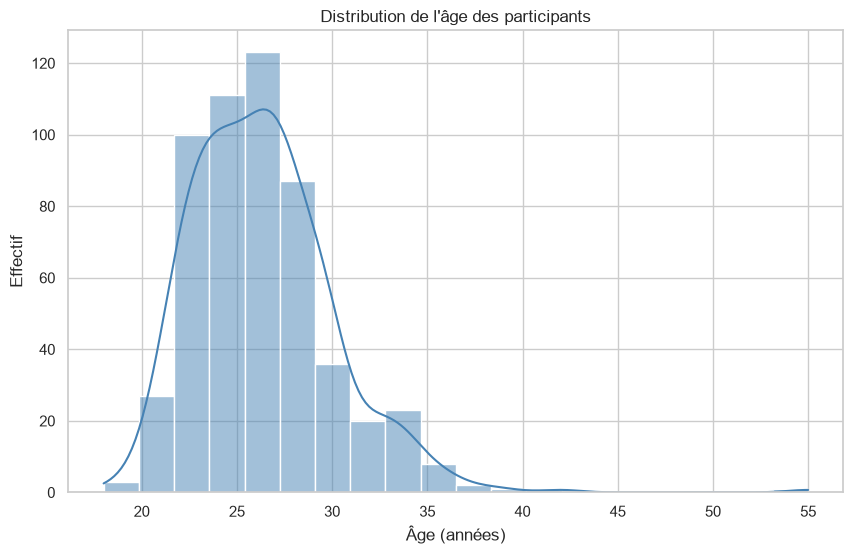

In [14]:
# Distribution de l'âge des participants (niveau personne pour éviter le poids
# des répétitions).
print("Distribution de l'âge des participants :")
print(personnes["age"].describe())

plt.figure(figsize=(10, 6))
sns.histplot(personnes["age"].dropna(), bins=20, kde=True, color="steelblue")
plt.title("Distribution de l'âge des participants")
plt.xlabel("Âge (années)")
plt.ylabel("Effectif")
plt.show()

In [15]:
# Moyennes, variances et écarts-types des six notes données et du score like.
notes_donnees = ["attr", "sinc", "intel", "fun", "amb", "shar"]
stats_notes = df_propre[notes_donnees + ["like"]].agg(["mean", "var", "std"])
print('Statistiques des notes données et du score "like" :')
print(stats_notes.round(3))

Statistiques des notes données et du score "like" :
       attr   sinc  intel    fun    amb   shar   like
mean  6.196  7.183  7.373  6.412  6.782  5.519  6.140
var   3.769  2.975  2.372  3.752  3.191  4.442  3.357
std   1.941  1.725  1.540  1.937  1.786  2.108  1.832


In [16]:
# Détection des anomalies par la règle de l'IQR sur chaque note.
print("Anomalies détectées par la règle de l'IQR :")
for col in notes_donnees + ["like"]:
    borne_inf, borne_sup, nb_anomalies = bornes_iqr(df_propre[col])
    print(f"  {col:<5} : {nb_anomalies:>4} anomalies hors [{borne_inf:.2f}, {borne_sup:.2f}]")

Anomalies détectées par la règle de l'IQR :
  attr  :    0 anomalies hors [0.50, 12.50]
  sinc  :  113 anomalies hors [3.00, 11.00]
  intel :   48 anomalies hors [3.00, 11.00]
  fun   :    0 anomalies hors [0.50, 12.50]
  amb   :  143 anomalies hors [3.00, 11.00]
  shar  :    0 anomalies hors [-0.50, 11.50]
  like  :  110 anomalies hors [2.00, 10.00]


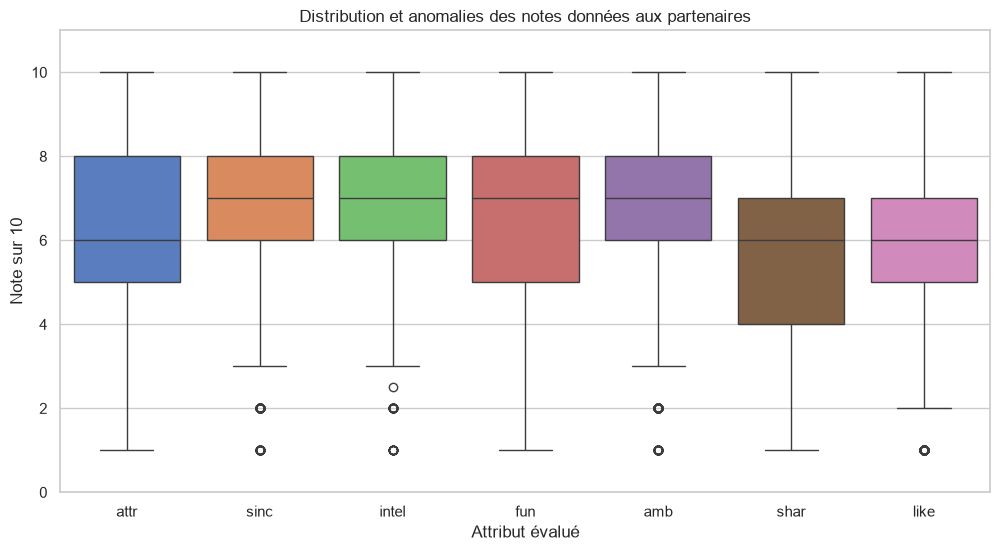

In [17]:
# Boîtes à moustaches des notes données et du score like.
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_propre[notes_donnees + ["like"]])
plt.title("Distribution et anomalies des notes données aux partenaires")
plt.xlabel("Attribut évalué")
plt.ylabel("Note sur 10")
plt.ylim(0, 11)
plt.show()

> **Interprétation** : sur 8 378 décisions, les participants disent oui dans 42,0 % des
> cas, mais le match réciproque, notre mesure du « second rendez-vous », n'arrive que dans
> 16,5 % des 4 184 rendez-vous : il faut que deux oui se rencontrent. Les notes moyennes
> données vont de 5,5/10 (goûts partagés) à 7,4/10 (intelligence) : on note plus
> généreusement la sincérité (7,2) et l'intelligence (7,4) que l'attirance (6,2). L'attirance, le fun et
> les goûts partagés ont les plus fortes variances (3,8 ; 3,8 ; 4,4) : ce sont les critères sur
> lesquels les participants se départagent le plus. La règle de l'écart interquartile signale
> des notes basses atypiques pour la sincérité (113), l'intelligence (48), l'ambition (143) et
> l'appréciation globale (110). Ce ne sont pas des erreurs de saisie (les valeurs hors de
> l'échelle 1-10 ont déjà été invalidées en section 2) mais des jugements sévères : on les
> conserve, car ils font partie du phénomène étudié. Âge médian : 26 ans (de 18 à 55 ans).

## 4. Analyse multivariée

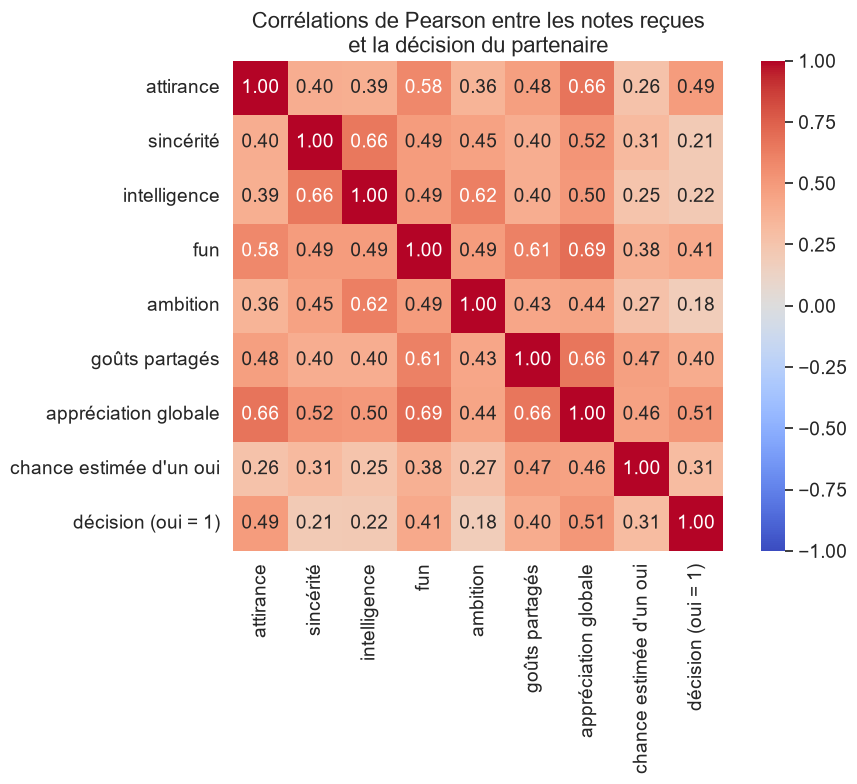

In [18]:
# (a) Matrice de Pearson entre les six notes reçues, like, prob et dec.
cols_corr = [
    "attr_o",
    "sinc_o",
    "intel_o",
    "fun_o",
    "amb_o",
    "shar_o",
    "like_o",
    "prob_o",
    "dec_o",
]
# Libellés en français pour que la matrice se lise sans dictionnaire des variables.
libelles_corr = {
    "attr_o": "attirance",
    "sinc_o": "sincérité",
    "intel_o": "intelligence",
    "fun_o": "fun",
    "amb_o": "ambition",
    "shar_o": "goûts partagés",
    "like_o": "appréciation globale",
    "prob_o": "chance estimée d'un oui",
    "dec_o": "décision (oui = 1)",
}
matrice_corr = df_propre[cols_corr].rename(columns=libelles_corr).corr(method="pearson")

# Taille des textes, en points : la figure est posée à environ 6 pouces de large sur la
# diapositive 4 du support, soit à peu près 0,6 fois sa taille réelle ; à 14 points, les
# coefficients et les étiquettes y restent au-dessus de 8 points.
TAILLE_TEXTE_PEARSON = 14
plt.figure(figsize=(10, 8))
carte = sns.heatmap(
    matrice_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    vmin=-1,
    vmax=1,
    annot_kws={"size": TAILLE_TEXTE_PEARSON},
)
carte.tick_params(labelsize=TAILLE_TEXTE_PEARSON)
# L'échelle de couleurs est le dernier des deux axes de la figure : mêmes graduations agrandies.
plt.gcf().axes[-1].tick_params(labelsize=TAILLE_TEXTE_PEARSON)
plt.title(
    "Corrélations de Pearson entre les notes reçues\net la décision du partenaire",
    fontsize=TAILLE_TEXTE_PEARSON + 2,
)
plt.tight_layout()  # garde les étiquettes agrandies dans le cadre de la figure
plt.show()

> **Interprétation** : la décision du partenaire est surtout liée à son appréciation
> globale (r = 0,51), à l'attirance (0,49), au fun (0,41) et aux goûts partagés (0,40) ; la
> sincérité (0,21), l'intelligence (0,22) et l'ambition (0,18) y sont beaucoup moins liées. Les
> notes sont aussi corrélées entre elles (sincérité-intelligence 0,66 ; intelligence-ambition
> 0,62) : c'est un effet de halo : qui plaît reçoit de bonnes notes partout. D'où la régression
> du point (c), qui isole l'effet propre de chaque critère, à notes égales sur les autres.

In [19]:
# (b) Ce qui fait dire « oui » aux femmes et aux hommes : corrélation entre chaque
# note que le participant donne à son partenaire et sa propre décision ('dec'),
# calculée séparément selon le sexe du participant.
corr_par_sexe = df_propre.groupby("gender")[notes_donnees + ["dec"]].corr()
corr_avec_dec = corr_par_sexe.xs("dec", level=1).drop(columns="dec")
corr_avec_dec.index = corr_avec_dec.index.map({0: "Femmes", 1: "Hommes"})

print("Corrélation entre chaque note donnée et la décision « oui » du participant :")
print(corr_avec_dec.round(3))

Corrélation entre chaque note donnée et la décision « oui » du participant :
         attr   sinc  intel    fun    amb   shar
gender                                          
Femmes  0.445  0.223  0.232  0.416  0.176  0.409
Hommes  0.515  0.190  0.216  0.408  0.219  0.395


> **Interprétation** : pour les deux sexes, la décision suit d'abord l'attirance
> (r = 0,45 chez les femmes, 0,52 chez les hommes), puis le fun (0,42 et 0,41) et les goûts
> partagés perçus (0,41 et 0,40) ; la sincérité, l'intelligence et l'ambition n'y sont liées
> qu'autour de 0,2. Le profil est donc proche d'un sexe à l'autre, avec une attirance un peu
> plus déterminante chez les hommes. Ces corrélations sont brutes : comme les notes se
> tiennent entre elles (effet de halo, point a), la régression qui suit mesure l'effet propre
> de chaque critère, à notes égales sur les autres.

In [20]:
# (c) Préférences déclarées vs importance révélée.
# Moyennes des préférences déclarées normalisées par sexe.
prefs_norm = [c + "_norm" for c in prefs_t1]
moyennes_declarees = personnes.groupby("gender")[prefs_norm].mean()
print("Préférences déclarées moyennes par sexe (points / 100) :")
print(moyennes_declarees.round(2))

Préférences déclarées moyennes par sexe (points / 100) :
        attr1_1_norm  sinc1_1_norm  intel1_1_norm  fun1_1_norm  amb1_1_norm  \
gender                                                                        
0              17.94         18.25          20.94        17.33        12.83   
1              26.99         16.35          19.40        17.57         8.75   

        shar1_1_norm  
gender                
0              12.70  
1              10.94  


In [21]:
# Outil commun à toutes les régressions logistiques du notebook : logit_grappes, importé en
# cellule 2 et défini dans speed_dating.py (testé par tests/test_speed_dating.py).
# Pourquoi des erreurs standard « groupées » ? Les lignes ne sont pas indépendantes : un même
# participant prend 5 à 22 décisions (ses décisions se ressemblent), et un même partenaire
# reçoit 5 à 22 décisions (un partenaire apprécié reçoit beaucoup de oui). Ignorer ces deux
# dépendances donnerait des p-valeurs trop petites. On groupe donc les erreurs sur DEUX
# dimensions à la fois, le participant (iid) et le partenaire (pid) : c'est l'estimateur à deux
# voies de Cameron, Gelbach et Miller (2011), que statsmodels calcule quand on lui passe deux
# colonnes de groupes. Les coefficients ne changent pas ; seule leur incertitude est corrigée.
# Les lignes incomplètes sont retirées AVANT l'ajustement ; l'effectif utilisé est modele.nobs.

In [22]:
# Régression logistique par sexe : dec ~ six notes standardisées.
# Attention au sens des variables : 'dec' est la décision du participant sur son
# partenaire ; elle s'explique donc par les notes que le PARTICIPANT a données à ce
# partenaire ('attr', 'sinc', ...), et non par les notes reçues ('attr_o', ...).
# C'est la préférence « révélée » : ce qui fait réellement dire oui.
# Unité : la décision (df_propre) ; erreurs groupées par participant ET par partenaire.
notes_standard = ["attr", "sinc", "intel", "fun", "amb", "shar"]
resultats_logit = {}

for sexe, label in [(0, "Femmes"), (1, "Hommes")]:
    # On retire d'abord les lignes incomplètes, puis on standardise sur ces mêmes lignes :
    # un coefficient se lit alors « pour une note plus haute d'un écart-type ».
    decisions_sexe = df_propre[df_propre["gender"] == sexe]
    complet = decisions_sexe.dropna(subset=notes_standard + ["dec", "pid"])
    sous_df = ajouter_z(complet, notes_standard)

    formule = "dec ~ " + " + ".join([n + "_z" for n in notes_standard])
    modele = logit_grappes(formule, sous_df, ["iid", "pid"])
    resultats_logit[label] = modele
    print(f"\nRégression logistique : {label}")
    print(
        f"Effectif : {int(modele.nobs)} décisions complètes sur {len(decisions_sexe)} "
        f"({1 - modele.nobs / len(decisions_sexe):.0%} retirées pour une note manquante), "
        f"{sous_df['iid'].nunique()} participants, {sous_df['pid'].nunique()} partenaires"
    )
    print(modele.summary().tables[1])
    rapports = rapports_de_cotes(modele.params[[n + "_z" for n in notes_standard]]).round(2)
    print("Rapports de cotes (× chances de dire oui pour +1 écart-type) :", rapports.to_dict())


Régression logistique : Femmes
Effectif : 3419 décisions complètes sur 4184 (18% retirées pour une note manquante), 268 participants, 277 partenaires
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.7695      0.104     -7.374      0.000      -0.974      -0.565
attr_z         0.8081      0.101      8.018      0.000       0.611       1.006
sinc_z        -0.1555      0.115     -1.348      0.178      -0.382       0.071
intel_z        0.1935      0.098      1.973      0.048       0.001       0.386
fun_z          0.5510      0.091      6.080      0.000       0.373       0.729
amb_z         -0.3110      0.091     -3.434      0.001      -0.489      -0.134
shar_z         0.5917      0.084      7.067      0.000       0.428       0.756
Rapports de cotes (× chances de dire oui pour +1 écart-type) : {'attr_z': 2.24, 'sinc_z': 0.86, 'intel_z': 1.21, 'fun_z': 1.74, 'amb_z': 0

In [23]:
# L'attirance pèse-t-elle VRAIMENT plus chez les hommes ? Comparer deux coefficients estimés
# séparément ne suffit pas : on teste la différence dans un modèle commun aux deux sexes, avec
# une interaction « note × homme » pour chaque critère (notes standardisées dans chaque sexe,
# comme ci-dessus ; erreurs groupées à deux voies). H0 : même poids de l'attirance pour les deux.
toutes_decisions = []
for sexe in (0, 1):
    partie = df_propre[df_propre["gender"] == sexe].dropna(subset=notes_standard + ["dec", "pid"])
    toutes_decisions.append(ajouter_z(partie, notes_standard))
decisions_communes = pd.concat(toutes_decisions)
decisions_communes["homme"] = decisions_communes["gender"]
formule_commune = "dec ~ (" + " + ".join(n + "_z" for n in notes_standard) + ") * homme"
modele_commun = logit_grappes(formule_commune, decisions_communes, ["iid", "pid"])
print(
    f"Différence hommes moins femmes du coefficient de l'attirance : "
    f"{modele_commun.params['attr_z:homme']:+.3f} (log-cote), "
    f"p = {modele_commun.pvalues['attr_z:homme']:.2e}"
)

Différence hommes moins femmes du coefficient de l'attirance : +0.439 (log-cote), p = 1.03e-03


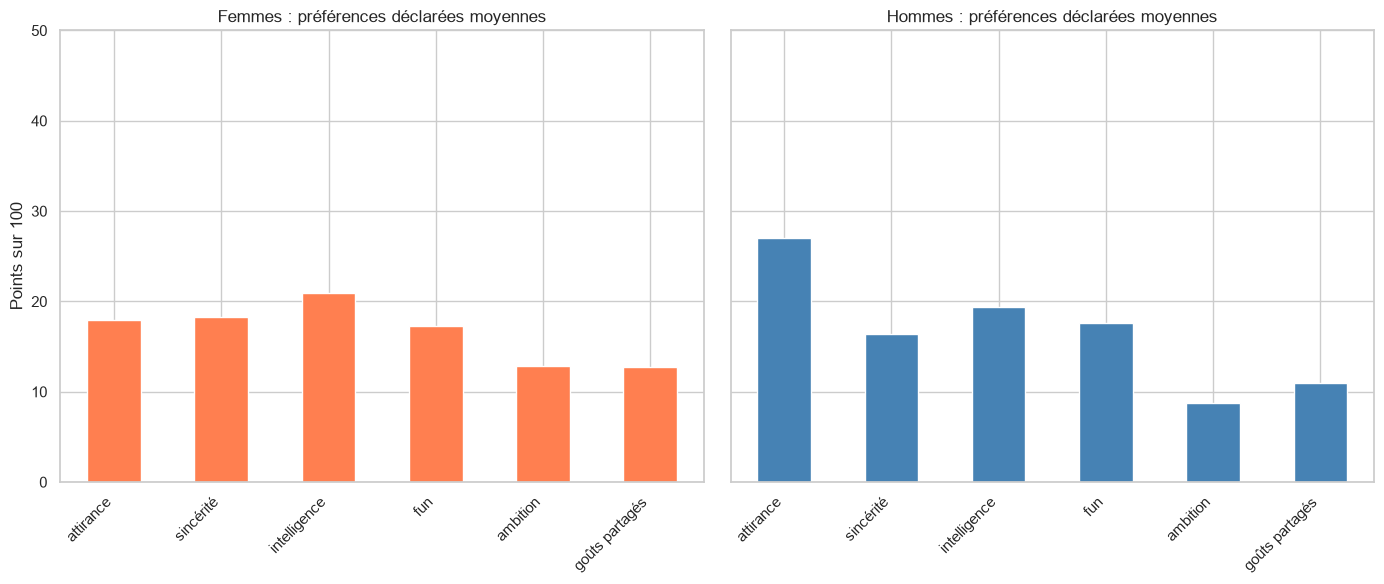

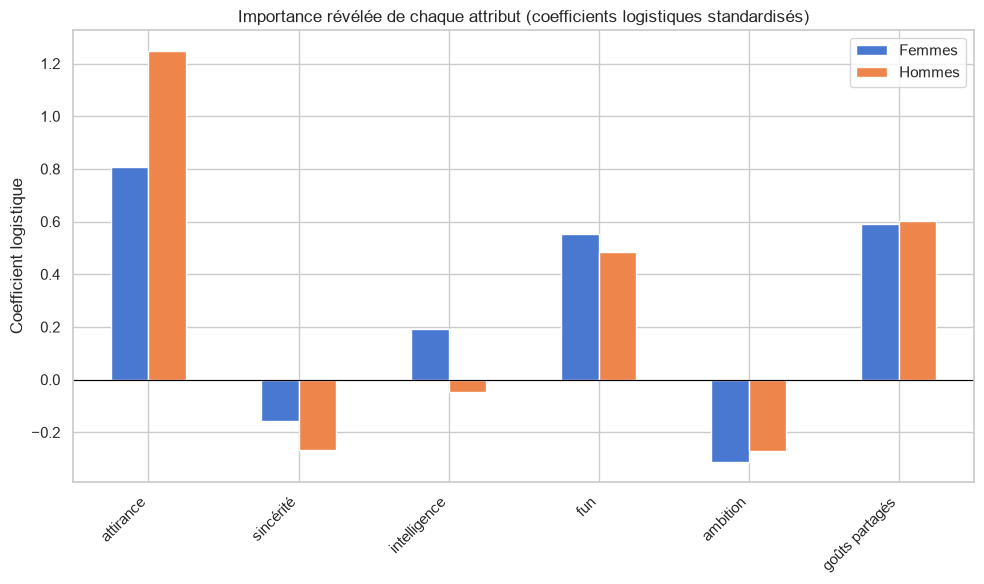

In [24]:
# Graphique côte à côte : préférences déclarées par sexe.
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# « goûts partagés » traduit `shar` (note du soir) et `shar1_1` (importance déclarée) ; à ne pas
# confondre avec `int_corr`, la proximité des centres d'intérêt déclarés (tests d et graphique 4).
labels_notes = ["attirance", "sincérité", "intelligence", "fun", "ambition", "goûts partagés"]

moyennes_declarees.loc[0].plot(kind="bar", ax=axes[0], color="coral")
axes[0].set_title("Femmes : préférences déclarées moyennes")
axes[0].set_ylabel("Points sur 100")
axes[0].set_ylim(0, 50)
axes[0].set_xticklabels(labels_notes, rotation=45, ha="right")

moyennes_declarees.loc[1].plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Hommes : préférences déclarées moyennes")
axes[1].set_ylabel("Points sur 100")
axes[1].set_ylim(0, 50)
axes[1].set_xticklabels(labels_notes, rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Graphique de l'importance révélée (coefficients logistiques standardisés).
coefs_reveles = pd.DataFrame(
    {
        "Femmes": resultats_logit["Femmes"].params[[n + "_z" for n in notes_standard]].values,
        "Hommes": resultats_logit["Hommes"].params[[n + "_z" for n in notes_standard]].values,
    },
    index=labels_notes,
)

coefs_reveles.plot(kind="bar", figsize=(10, 6))
plt.title("Importance révélée de chaque attribut (coefficients logistiques standardisés)")
plt.ylabel("Coefficient logistique")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

> **Interprétation** : les femmes déclarent d'abord chercher l'intelligence (20,9 points
> sur 100) et la sincérité (18,3), l'attirance ne venant qu'en troisième (17,9) ; les hommes
> placent l'attirance en tête (27,0), loin devant l'intelligence (19,4).
>
> Les décisions (3 419 décisions complètes de 268 femmes, 3 545 de 269 hommes) montrent, à
> notes égales sur les autres critères, que l'attirance est le premier moteur du oui pour les
> deux sexes : une note plus haute d'un écart-type multiplie la cote du oui (le rapport des
> chances de oui sur non) par 2,2 chez les femmes et par 3,5 chez les hommes ; cette
> différence entre sexes est testée dans un modèle commun (interaction « attirance × homme » :
> +0,44 en log-cote, p = 0,001, sous le seuil corrigé). Viennent ensuite
> les goûts partagés perçus (× 1,8 pour les deux sexes) et le fun (× 1,7 et × 1,6).
> L'ambition a un effet propre négatif pour les deux sexes (× 0,73 et × 0,76), la sincérité
> aussi chez les hommes (× 0,76) : à attirance et fun égaux, juger quelqu'un plus « sérieux »
> ne fait pas dire oui plus souvent. L'intelligence n'a pas d'effet démontré, ni chez les
> hommes (p = 0,58) ni chez les femmes (p = 0,048, au-dessus du seuil corrigé).
>
> **Famille de tests** : ces deux régressions estiment douze coefficients. Pour ne pas
> multiplier les fausses découvertes, on les lit au seuil de Bonferroni 0,05 / 12 ≈ 0,0042 :
> l'attirance, les goûts partagés, le fun et l'ambition (deux sexes) et la sincérité (hommes)
> le passent ; l'intelligence chez les femmes, non. Les erreurs standard sont groupées par
> participant et par partenaire (section 4, outil `logit_grappes`) ; 15 à 18 % des décisions
> sont écartées faute d'une note complète.
>
> **Déclaré contre révélé** : l'écart est net chez les femmes (elles placent l'intelligence et
> la sincérité en tête, leurs choix suivent l'attirance, les goûts partagés et le fun) ; chez
> les hommes, l'attirance est première dans les deux cas. Les deux mesures n'ont pas la même
> échelle (points sur 100 contre rapport de cotes) : on compare l'ordre des critères, pas
> leur valeur. Le point (c bis) teste si les préférences déclarées pèsent dans les décisions.

**(c bis) Les préférences déclarées prédisent-elles les décisions ?** Si l'importance qu'une
personne déclare accorder à un critère guidait vraiment ses choix, ce critère devrait peser
davantage dans les décisions de ceux qui le déclarent important. On le teste par une
**interaction** : pour chaque sexe et chaque critère k, on ajoute au modèle précédent
l'importance déclarée de k et le produit « note donnée sur k × importance déclarée de k ».
H0 : le coefficient de ce produit est nul (le poids du critère ne dépend pas de ce qu'on
déclare). Douze tests (6 critères × 2 sexes) : seuil de Bonferroni 0,05 / 12.

In [25]:
importances = {
    "attr": "attr1_1_norm",
    "sinc": "sinc1_1_norm",
    "intel": "intel1_1_norm",
    "fun": "fun1_1_norm",
    "amb": "amb1_1_norm",
    "shar": "shar1_1_norm",
}
libelle_critere = dict(zip(notes_standard, labels_notes, strict=True))
SEUIL_INTERACTIONS = 0.05 / 12
lignes_interactions = []

for sexe, label in [(0, "Femmes"), (1, "Hommes")]:
    colonnes_utiles = notes_standard + list(importances.values()) + ["dec", "pid"]
    # Standardisation de toutes les variables sur les mêmes lignes : coefficients comparables.
    sous_df = ajouter_z(
        df_propre[df_propre["gender"] == sexe].dropna(subset=colonnes_utiles),
        notes_standard + list(importances.values()),
    )
    base = " + ".join(n + "_z" for n in notes_standard)
    for note, importance in importances.items():
        terme = f"{note}_z:{importance}_z"
        modele = logit_grappes(f"dec ~ {base} + {importance}_z + {terme}", sous_df, ["iid", "pid"])
        lignes_interactions.append(
            {
                "sexe": label,
                "critère": libelle_critere[note],
                "interaction (log-cote)": round(modele.params[terme], 3),
                "p-valeur": round(modele.pvalues[terme], 3),
                "significatif (Bonferroni)": modele.pvalues[terme] < SEUIL_INTERACTIONS,
                "décisions": int(modele.nobs),
            }
        )

tableau_interactions = pd.DataFrame(lignes_interactions)
print(f"Seuil de Bonferroni pour les 12 interactions : {SEUIL_INTERACTIONS:.4f}")
print(
    f"Interactions significatives à 5 % (sans correction) : "
    f"{(tableau_interactions['p-valeur'] < 0.05).sum()} sur 12"
)
tableau_interactions

Seuil de Bonferroni pour les 12 interactions : 0.0042
Interactions significatives à 5 % (sans correction) : 1 sur 12


,sexe,critère,interaction (log-cote),p-valeur,significatif (Bonferroni),décisions
0,Femmes,attirance,0.002,0.992,False,3350
1,Femmes,sincérité,0.034,0.766,False,3350
2,Femmes,intelligence,-0.015,0.873,False,3350
3,Femmes,fun,-0.024,0.783,False,3350
4,Femmes,ambition,-0.019,0.743,False,3350
5,Femmes,goûts partagés,0.104,0.225,False,3350
6,Hommes,attirance,0.198,0.047,False,3510
7,Hommes,sincérité,-0.033,0.646,False,3510
8,Hommes,intelligence,0.013,0.895,False,3510
9,Hommes,fun,0.038,0.655,False,3510


> **Interprétation** : aucune des douze interactions ne passe le seuil corrigé (0,0042). Une
> seule passe 5 % sans correction (hommes, attirance : p = 0,047), ce qu'on attend du hasard
> sur douze tests (0,6 faux positif en moyenne). Autrement dit, une femme qui déclare tenir à
> l'intelligence ne pèse pas, de façon démontrée, l'intelligence plus lourdement dans ses
> choix qu'une femme qui n'y tient pas ; il en va de même pour chaque critère et chaque sexe.
> **Prudence** : ne pas démontrer un effet ne prouve pas son absence (la puissance d'un test
> d'interaction est limitée). La conclusion exacte est donc : *dans ces données, rien ne
> montre que les préférences déclarées à l'inscription guident les décisions du soir*.

Corrélation attr3_1 contre attr_o moyen : 0.288


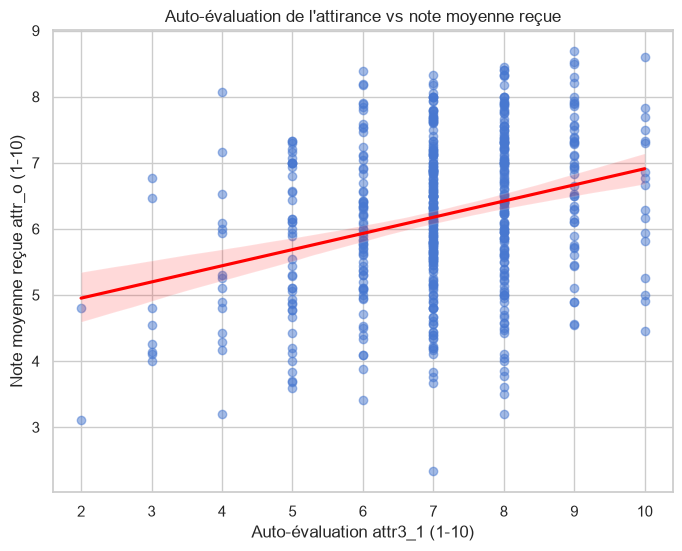

In [26]:
# (d) Auto-perception : attr3_1 vs note moyenne reçue attr_o.
correlation_auto = personnes[["attr3_1", "attr_o_moyen"]].corr().iloc[0, 1]
print(f"Corrélation attr3_1 contre attr_o moyen : {correlation_auto:.3f}")

plt.figure(figsize=(8, 6))
sns.regplot(
    data=personnes,
    x="attr3_1",
    y="attr_o_moyen",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
)
plt.title("Auto-évaluation de l'attirance vs note moyenne reçue")
plt.xlabel("Auto-évaluation attr3_1 (1-10)")
plt.ylabel("Note moyenne reçue attr_o (1-10)")
plt.show()

> **Interprétation** : la corrélation entre l'auto-évaluation d'attirance et la note
> moyenne reçue n'est que de 0,29 : on se connaît mal. Les participants se donnent en moyenne
> 7,1/10 quand leurs partenaires leur donnent 6,2 ; l'écart est testé au point 5 (f).

In [27]:
# (e) Proximité des centres d'intérêt déclarés et même origine.
# Ces deux variables décrivent le rendez-vous (identiques sur ses deux lignes) : on travaille
# sur rdv, une ligne par rendez-vous, pour ne pas compter chaque rendez-vous deux fois.
# Taux de match par quintile de int_corr (corrélation des centres d'intérêt déclarés).
quintiles_int = pd.qcut(rdv["int_corr"], q=5, duplicates="drop")
taux_match_int = rdv.groupby(quintiles_int, observed=True)["match"].agg(["mean", "size"])
taux_match_int["mean"] *= 100
taux_match_int.columns = ["taux de match (%)", "rendez-vous"]
print("Taux de match par quintile de proximité des centres d'intérêt (int_corr) :")
print(taux_match_int.round(2))

# Taux de match selon l'origine commune.
tableau_samerace = rdv.groupby("samerace")["match"].agg(["mean", "size"])
tableau_samerace["mean"] *= 100
tableau_samerace.columns = ["taux de match (%)", "rendez-vous"]
tableau_samerace.index = tableau_samerace.index.map({0: "origines différentes", 1: "même origine"})
print("Taux de match selon la même origine :")
print(tableau_samerace.round(2))

Taux de match par quintile de proximité des centres d'intérêt (int_corr) :
                 taux de match (%)  rendez-vous
int_corr                                       
(-0.831, -0.07]              15.07          843
(-0.07, 0.13]                15.64          857
(0.13, 0.3]                  15.71          770
(0.3, 0.48]                  16.69          857
(0.48, 0.91]                 19.28          778
Taux de match selon la même origine :
                      taux de match (%)  rendez-vous
samerace                                            
origines différentes              16.11         2526
même origine                      17.07         1658


> **Interprétation** : le taux de match monte de 15,1 % (quintile de proximité des centres
> d'intérêt le plus faible) à 19,3 % (le plus fort), avec des quintiles intermédiaires très
> proches (15,6 à 16,7 %). Les rendez-vous entre personnes de même origine déclarée matchent
> à 17,1 %, contre 16,1 % sinon. Ces écarts sont petits : la section 5 teste s'ils dépassent
> ce que le hasard produit (tests c et d).

Taux de "oui" selon le rang du rendez-vous :
order
1     49.91
2     39.38
3     42.11
4     44.65
5     42.29
6     44.18
7     41.63
8     40.94
9     44.42
10    41.98
11    40.05
12    37.37
13    40.59
14    41.67
15    40.12
16    39.80
17    37.55
18    39.53
19    47.75
20    39.58
21    33.72
22    38.64
Name: dec, dtype: float64


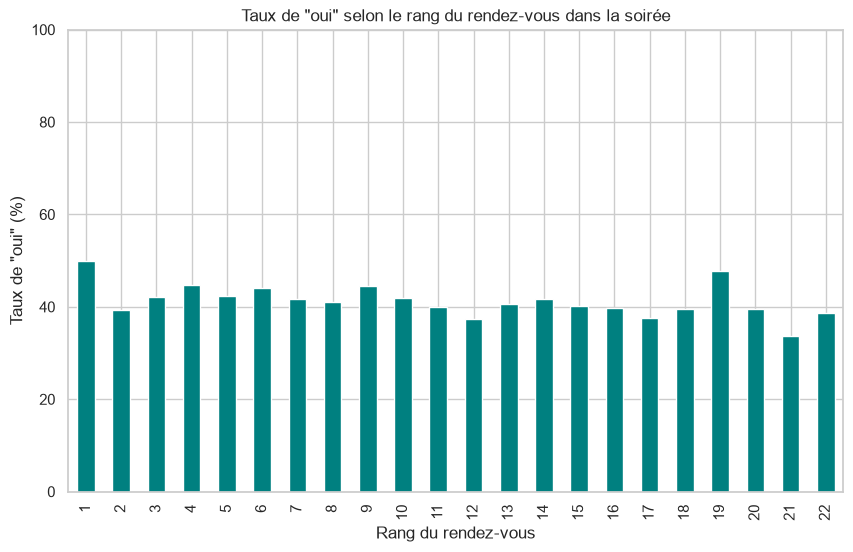

In [28]:
# (f) Effet d'ordre : taux de "oui" selon le rang du rendez-vous.
taux_dec_par_order = df_propre.groupby("order")["dec"].mean() * 100
print('Taux de "oui" selon le rang du rendez-vous :')
print(taux_dec_par_order.round(2))

plt.figure(figsize=(10, 6))
taux_dec_par_order.plot(kind="bar", color="teal")
plt.title('Taux de "oui" selon le rang du rendez-vous dans la soirée')
plt.xlabel("Rang du rendez-vous")
plt.ylabel('Taux de "oui" (%)')
plt.ylim(0, 100)
plt.show()

> **Interprétation** : le premier rendez-vous de la soirée obtient le plus de oui
> (49,9 %) ; ensuite, le taux oscille entre 34 % et 48 % sans tendance nette (41,4 % en
> moyenne après le premier). L'effet du rang est testé au point 5 (e).

## 5. Raisonnement statistique : les écarts observés sont-ils dus au hasard ?

Méthode commune à tous les tests :

- hypothèses **H0** (pas d'effet) et **H1** (effet), niveau α = 5 % ;
- **chaque test porte sur son unité naturelle**, car les lignes ne sont pas indépendantes
  (traiter des observations liées comme indépendantes gonflerait artificiellement la
  significativité : c'est la pseudo-réplication) :
  - **la personne** (`personnes`, une ligne par participant) quand la question porte sur un
    trait individuel : tests (a), (b), (f) ;
  - **le rendez-vous** (`rdv`, une ligne par rendez-vous) quand la variable est la même pour
    les deux partenaires (`match`, `samerace`, `int_corr`) : tests (c), (d). Les garder en
    double compterait chaque rendez-vous deux fois, et grouper par participant ne suffirait
    pas : les deux lignes d'un rendez-vous appartiennent à deux participants différents ;
  - **la décision** (`df_propre`) quand la variable est propre à celui qui décide (`dec`,
    `order`) : test (e) ;
  - pour les régressions (c), (d), (e), erreurs standard **groupées à deux voies** (participant
    et partenaire ; outil `logit_grappes`, section 4), car une même personne revient dans
    plusieurs rendez-vous des deux côtés ;
- chaque p-valeur est accompagnée d'une **taille d'effet** : avec des milliers de lignes, un
  effet minuscule peut être « significatif » sans aucune importance pratique ;
- six tests sont menés : on applique la **correction de Bonferroni** (seuil α / 6 ≈ 0,0083).
  Elle reste valable même si les tests ne sont pas indépendants (elle est alors prudente).

In [29]:
# Constantes et outils communs aux six tests.
ALPHA = 0.05
NB_TESTS = 6
SEUIL_BONFERRONI = ALPHA / NB_TESTS

# Liste des résultats : chaque test y ajoute une ligne, pour le tableau récapitulatif final.
resultats_tests: list[dict[str, str]] = []

# consigner(nom, h0, unité, statistique, p, effet) : formater_p et consigner_test viennent de
# speed_dating.py ; la décision est prise au seuil de Bonferroni (H0 rejetée si p < seuil).
consigner = partial(consigner_test, resultats_tests, SEUIL_BONFERRONI)

### (a) Les hommes déclarent-ils accorder plus d'importance à l'attirance que les femmes ?

H0 : l'importance moyenne déclarée de l'attirance (points sur 100, après normalisation) est la
même pour les deux sexes ; H1 : elle diffère. Unité : la personne (une valeur par participant).

Choix du test : deux groupes indépendants de plusieurs centaines de personnes ; à ces
effectifs, le théorème central limite rend le test de Student robuste à la non-normalité. Le
test de Levene indique si les variances diffèrent ; on retient de toute façon le test de
**Welch**, qui ne suppose pas l'égalité des variances.

In [30]:
attr_femmes = personnes.loc[personnes["gender"] == 0, "attr1_1_norm"].dropna()
attr_hommes = personnes.loc[personnes["gender"] == 1, "attr1_1_norm"].dropna()

stat_levene, p_levene = stats.levene(attr_femmes, attr_hommes)
stat_welch, p_welch = stats.ttest_ind(attr_hommes, attr_femmes, equal_var=False)
# d de Cohen calculé avec l'écart-type moyen des deux groupes (convention usuelle avec Welch).
d_welch = d_cohen(attr_hommes, attr_femmes)

print(f"Effectifs : {len(attr_femmes)} femmes, {len(attr_hommes)} hommes")
print(
    f"Importance moyenne déclarée : femmes {attr_femmes.mean():.1f} pts, "
    f"hommes {attr_hommes.mean():.1f} pts"
)
print(f"Levene : W = {stat_levene:.2f}, p = {formater_p(p_levene)}")
print(f"Welch : t = {stat_welch:.2f}, p = {formater_p(p_welch)}, d de Cohen = {d_welch:.2f}")
consigner(
    "(a) Welch : importance déclarée de l'attirance, hommes contre femmes",
    "moyennes égales",
    "personne",
    f"t = {stat_welch:.2f}",
    p_welch,
    f"d = {d_welch:.2f}",
)

Effectifs : 268 femmes, 273 hommes
Importance moyenne déclarée : femmes 17.9 pts, hommes 27.0 pts
Levene : W = 15.14, p = 1.12e-04
Welch : t = 8.85, p = 1.51e-17, d de Cohen = 0.76


### (b) Ceux qui disent « oui » à une personne la trouvent-ils plus attirante ?

Pour chaque participant, on calcule la note d'attirance moyenne qu'il a reçue des partenaires
qui lui ont dit oui, et celle reçue des partenaires qui lui ont dit non ; on compare ces deux
moyennes **pour la même personne** (mesures appariées). Cette construction neutralise
l'attrait propre de chaque personne : on compare une personne à elle-même.

H0 : la différence médiane (note si oui moins note si non) est nulle. Test : **Wilcoxon signé**,
apparié et non paramétrique (les notes sont bornées entre 1 et 10 et la différence n'a pas de
raison d'être normale). Taille d'effet : corrélation de rang bisériale appariée (entre -1 et 1).

**Limite de lecture** : la note d'attirance et la décision sont données par le même partenaire,
sur la même fiche, à la fin du même rendez-vous. Un effet fort est donc attendu, en partie par
construction : ce test mesure la **cohérence** entre le jugement et le choix, pas une cause.
Il ne dit pas si l'on dit oui parce qu'on trouve la personne attirante, ou si l'on se justifie
son oui par une bonne note. La régression de la section 4 (c) va plus loin : elle mesure le
poids de l'attirance **à notes égales sur les autres critères**.

In [31]:
notes_par_decision = (
    df_propre.dropna(subset=["attr_o", "dec_o"])
    .groupby(["iid", "dec_o"])["attr_o"]
    .mean()
    .unstack()
    .dropna()  # on garde les personnes qui ont reçu au moins un oui ET au moins un non
)
notes_par_decision.columns = ["note_si_non", "note_si_oui"]
ecarts_notes = notes_par_decision["note_si_oui"] - notes_par_decision["note_si_non"]

stat_wilcoxon, p_wilcoxon = stats.wilcoxon(ecarts_notes)
# Rang bisérial apparié : (somme des rangs des écarts positifs moins celle des négatifs) / somme des rangs.
r_bisserial = rang_bisserial_apparie(ecarts_notes)

print(f"Personnes comparées : {len(ecarts_notes)}")
print(
    f"Note d'attirance médiane reçue : {notes_par_decision['note_si_oui'].median():.2f} si oui, "
    f"{notes_par_decision['note_si_non'].median():.2f} si non"
)
print(f"Part des personnes mieux notées par ceux qui disent oui : {(ecarts_notes > 0).mean():.1%}")
print(
    f"Wilcoxon : W = {stat_wilcoxon:.0f}, p = {formater_p(p_wilcoxon)}, "
    f"rang bisérial = {r_bisserial:.2f}"
)
consigner(
    "(b) Wilcoxon apparié : note d'attirance reçue si oui contre si non",
    "différence médiane nulle",
    "personne",
    f"W = {stat_wilcoxon:.0f}",
    p_wilcoxon,
    f"r = {r_bisserial:.2f}",
)

Personnes comparées : 525
Note d'attirance médiane reçue : 7.17 si oui, 5.71 si non
Part des personnes mieux notées par ceux qui disent oui : 89.0%
Wilcoxon : W = 5052, p = 1.10e-74, rang bisérial = 0.93


### (c) Être de même origine augmente-t-il les chances de match ?

H0 : la probabilité de match ne dépend pas de `samerace`. Unité : **le rendez-vous** (base
`rdv`, une ligne par rendez-vous : `match` et `samerace` sont identiques sur les deux lignes
d'un même rendez-vous). On présente le **chi-deux** et le **V de Cramér** (taille d'effet),
puis on décide avec une régression logistique `match ~ samerace` à erreurs groupées à deux
voies (la participante et le participant), car chaque personne a plusieurs rendez-vous.

In [32]:
donnees_origine = rdv.dropna(subset=["samerace", "match"])
tableau_origine = pd.crosstab(donnees_origine["samerace"], donnees_origine["match"])
chi2_origine, p_chi2_origine, ddl_origine, _ = stats.chi2_contingency(tableau_origine)
v_origine = v_cramer(tableau_origine, chi2_origine)
modele_origine = logit_grappes("match ~ samerace", donnees_origine, ["iid", "pid"])
p_origine = modele_origine.pvalues["samerace"]
z_origine = modele_origine.tvalues["samerace"]

print(f"Rendez-vous : {int(modele_origine.nobs)}")
print(
    "Taux de match :",
    (donnees_origine.groupby("samerace")["match"].mean() * 100)
    .round(1)
    .rename({0: "origines différentes", 1: "même origine"})
    .to_dict(),
    "(en %)",
)
print(
    f"Chi-deux (descriptif, suppose des rendez-vous indépendants) = {chi2_origine:.2f} "
    f"(ddl = {ddl_origine}), p = {formater_p(p_chi2_origine)}, V de Cramér = {v_origine:.3f}"
)
print(
    f"Logistique à grappes à deux voies (test retenu) : rapport de cotes = "
    f"{np.exp(modele_origine.params['samerace']):.2f}, z = {z_origine:.2f}, "
    f"p = {formater_p(p_origine)}"
)
# La statistique consignée est celle du test qui décide (z de la logistique), pour que la
# ligne du tableau soit cohérente avec sa p-valeur.
consigner(
    "(c) Logistique à deux voies : même origine et match",
    "pas d'association",
    "rendez-vous",
    f"z = {z_origine:.2f}",
    p_origine,
    f"V = {v_origine:.3f}",
)

Rendez-vous : 4184
Taux de match : {'origines différentes': 16.1, 'même origine': 17.1} (en %)
Chi-deux (descriptif, suppose des rendez-vous indépendants) = 0.60 (ddl = 1), p = 4.40e-01, V de Cramér = 0.012
Logistique à grappes à deux voies (test retenu) : rapport de cotes = 1.07, z = 0.60, p = 5.47e-01


### (d) La proximité des centres d'intérêt déclarés augmente-t-elle les chances de match ?

`int_corr` mesure la corrélation entre les centres d'intérêt que les deux partenaires ont
déclarés à l'inscription (sport, musique, lecture…), avant de se rencontrer. À ne pas confondre
avec `shar`, les goûts partagés **perçus** pendant le rendez-vous (section 4 c).
H0 : la probabilité de match ne dépend pas de `int_corr`. Unité : le rendez-vous (`rdv`),
régression logistique à grappes à deux voies. Taille d'effet : **rapport de cotes** pour une
hausse d'un écart-type de `int_corr` (au-dessus de 1 : chances accrues).

In [33]:
donnees_interets = rdv.dropna(subset=["int_corr", "match"]).copy()
ecart_type_int = donnees_interets["int_corr"].std()
donnees_interets["int_corr_z"] = (
    donnees_interets["int_corr"] - donnees_interets["int_corr"].mean()
) / ecart_type_int
modele_interets = logit_grappes("match ~ int_corr_z", donnees_interets, ["iid", "pid"])
rc_interets = np.exp(modele_interets.params["int_corr_z"])
p_interets = modele_interets.pvalues["int_corr_z"]

print(f"Rendez-vous : {int(modele_interets.nobs)} ; écart-type de int_corr : {ecart_type_int:.3f}")
print(f"Rapport de cotes pour +1 écart-type : {rc_interets:.3f}, p = {formater_p(p_interets)}")
# Sensibilité au choix des grappes, affichée pour la transparence : la conclusion ne doit pas
# dépendre d'un choix technique. Une seule dimension sous-estime l'incertitude (elle ignore la
# dépendance dans l'autre dimension) ; la décision repose sur les deux voies.
for libelle, grappes in [
    ("participante seule", ["iid"]),
    ("participant seul", ["pid"]),
    ("deux voies (retenu)", ["iid", "pid"]),
]:
    variante = logit_grappes("match ~ int_corr_z", donnees_interets, grappes)
    print(f"  p avec grappes « {libelle} » : {formater_p(variante.pvalues['int_corr_z'])}")
# Contre-exemple, pour montrer l'effet de la pseudo-réplication : le même test calculé À TORT
# sur les lignes de df_propre, où chaque rendez-vous compte deux fois (grappes par participant).
lignes_doublees = df_propre.dropna(subset=["int_corr", "match"]).copy()
lignes_doublees["int_corr_z"] = (
    lignes_doublees["int_corr"] - lignes_doublees["int_corr"].mean()
) / lignes_doublees["int_corr"].std()
modele_double = logit_grappes("match ~ int_corr_z", lignes_doublees, ["iid"])
print(
    f"  contre-exemple, à tort sur {int(modele_double.nobs)} lignes (rendez-vous doublés) : "
    f"p = {formater_p(modele_double.pvalues['int_corr_z'])}"
)
consigner(
    "(d) Logistique à deux voies : proximité des centres d'intérêt et match",
    "pas d'association",
    "rendez-vous",
    f"z = {modele_interets.tvalues['int_corr_z']:.2f}",
    p_interets,
    f"RC = {rc_interets:.2f} par écart-type",
)

Rendez-vous : 4105 ; écart-type de int_corr : 0.304
Rapport de cotes pour +1 écart-type : 1.087, p = 1.77e-01
  p avec grappes « participante seule » : 7.59e-02
  p avec grappes « participant seul » : 1.57e-01
  p avec grappes « deux voies (retenu) » : 1.77e-01
  contre-exemple, à tort sur 8220 lignes (rendez-vous doublés) : p = 2.47e-02


### (e) Le rang du rendez-vous dans la soirée influence-t-il la décision ?

H0 : la probabilité de dire oui ne dépend pas de `order` (rang du rendez-vous). Unité : la
décision (`df_propre`), régression logistique à grappes à deux voies. Taille d'effet : rapport
de cotes pour cinq rendez-vous de plus.

**Contrôle de la vague** : le rang maximal varie de 5 à 22 selon la vague, et les vagues
diffèrent par leur protocole (la documentation indique par exemple qu'à la vague 12 chacun ne
pouvait dire oui qu'à la moitié des personnes rencontrées ; la variable `condtn`, choix limité
ou étendu, est constante dans chaque vague). Un rang élevé signale donc aussi une vague
nombreuse. On ajoute des **effets fixes de vague** (`C(wave)`) : le rang n'est alors comparé
qu'à l'intérieur d'une même soirée, et tout ce qui est propre à une vague est neutralisé.

In [34]:
donnees_ordre = df_propre.dropna(subset=["dec", "order", "pid"])
modele_ordre_brut = logit_grappes("dec ~ order", donnees_ordre, ["iid", "pid"])
modele_ordre = logit_grappes("dec ~ order + C(wave)", donnees_ordre, ["iid", "pid"])
rc_ordre_5 = np.exp(5 * modele_ordre.params["order"])
p_ordre = modele_ordre.pvalues["order"]

# Taux descriptifs sur toutes les décisions, comme au point 4 (f).
taux_premier = df_propre.loc[df_propre["order"] == 1, "dec"].mean()
taux_suivants = df_propre.loc[df_propre["order"] > 1, "dec"].mean()
print(f"Décisions : {int(modele_ordre.nobs)}")
print(f"Taux de oui au 1er rendez-vous : {taux_premier:.1%} ; au-delà : {taux_suivants:.1%}")
print(
    f"Sans contrôle de la vague : RC pour +5 rangs = "
    f"{np.exp(5 * modele_ordre_brut.params['order']):.3f}, "
    f"p = {formater_p(modele_ordre_brut.pvalues['order'])}"
)
print(
    f"Avec effets fixes de vague (retenu) : RC pour +5 rangs = {rc_ordre_5:.3f}, "
    f"p = {formater_p(p_ordre)}"
)
consigner(
    "(e) Logistique à deux voies, effets fixes de vague : rang et décision",
    "pas d'effet du rang",
    "décision",
    f"z = {modele_ordre.tvalues['order']:.2f}",
    p_ordre,
    f"RC = {rc_ordre_5:.2f} pour +5 rangs",
)

Décisions : 8368
Taux de oui au 1er rendez-vous : 49.9% ; au-delà : 41.4%


Sans contrôle de la vague : RC pour +5 rangs = 0.942, p = 2.23e-02
Avec effets fixes de vague (retenu) : RC pour +5 rangs = 0.963, p = 5.75e-02


### (f) Se juge-t-on plus attirant que les autres ne nous jugent ?

Pour chaque participant : son auto-évaluation d'attirance avant l'événement (`attr3_1`, sur 10)
contre la note moyenne d'attirance reçue le soir (`attr_o_moyen`). Mesures appariées sur la
même personne. H0 : la différence moyenne est nulle. Test : **t de Student apparié** (plus de
500 personnes : la moyenne des différences est approximativement normale) ; taille d'effet :
d de Cohen apparié (différence moyenne / écart-type des différences).

In [35]:
personnes_auto = personnes.dropna(subset=["attr3_1", "attr_o_moyen"])
ecarts_auto = personnes_auto["attr3_1"] - personnes_auto["attr_o_moyen"]
stat_apparie, p_apparie = stats.ttest_rel(
    personnes_auto["attr3_1"], personnes_auto["attr_o_moyen"]
)
d_apparie = d_cohen_apparie(ecarts_auto)

print(f"Personnes : {len(personnes_auto)}")
print(
    f"Auto-évaluation moyenne : {personnes_auto['attr3_1'].mean():.2f} ; "
    f"note moyenne reçue : {personnes_auto['attr_o_moyen'].mean():.2f}"
)
print(f"Part des personnes qui se surestiment : {(ecarts_auto > 0).mean():.1%}")
print(
    f"Corrélation auto-évaluation / note reçue : "
    f"{personnes_auto[['attr3_1', 'attr_o_moyen']].corr().iloc[0, 1]:.2f}"
)
print(f"t apparié = {stat_apparie:.2f}, p = {formater_p(p_apparie)}, d = {d_apparie:.2f}")
consigner(
    "(f) t apparié : auto-évaluation contre note reçue",
    "différence moyenne nulle",
    "personne",
    f"t = {stat_apparie:.2f}",
    p_apparie,
    f"d = {d_apparie:.2f}",
)

Personnes : 542
Auto-évaluation moyenne : 7.09 ; note moyenne reçue : 6.20
Part des personnes qui se surestiment : 73.2%
Corrélation auto-évaluation / note reçue : 0.29
t apparié = 13.48, p = 6.20e-36, d = 0.58


In [36]:
# Tableau récapitulatif des six tests.
tableau_tests = pd.DataFrame(resultats_tests)
print(f"Seuil de Bonferroni : {ALPHA} / {NB_TESTS} = {SEUIL_BONFERRONI:.4f}")
tableau_tests

Seuil de Bonferroni : 0.05 / 6 = 0.0083


,test,H0,unité,statistique,p-valeur,taille d'effet,décision (Bonferroni)
0,(a) Welch : importance déclarée de l'attirance...,moyennes égales,personne,t = 8.85,1.51e-17,d = 0.76,H0 rejetée
1,(b) Wilcoxon apparié : note d'attirance reçue ...,différence médiane nulle,personne,W = 5052,1.10e-74,r = 0.93,H0 rejetée
2,(c) Logistique à deux voies : même origine et ...,pas d'association,rendez-vous,z = 0.60,5.47e-01,V = 0.012,H0 conservée
3,(d) Logistique à deux voies : proximité des ce...,pas d'association,rendez-vous,z = 1.35,1.77e-01,RC = 1.09 par écart-type,H0 conservée
4,"(e) Logistique à deux voies, effets fixes de v...",pas d'effet du rang,décision,z = -1.90,5.75e-02,RC = 0.96 pour +5 rangs,H0 conservée
5,(f) t apparié : auto-évaluation contre note reçue,différence moyenne nulle,personne,t = 13.48,6.20e-36,d = 0.58,H0 rejetée


> **Interprétation** : trois résultats sont solides, même après la correction de
> Bonferroni. (a) Les hommes déclarent accorder bien plus d'importance à l'attirance que les
> femmes (27,0 contre 17,9 points ; d = 0,76, effet moyen à fort). (b) Pour 89 % des
> participants, ceux qui leur disent oui les ont trouvés plus attirants que ceux qui disent non
> (médiane 7,2 contre 5,7 ; r = 0,93) : c'est cohérent, mais en partie mécanique, puisque la
> note et la décision viennent de la même fiche (limite de lecture, point b). (f) 73 % des
> participants se surestiment (7,1 contre 6,2 en moyenne ; d = 0,58).
>
> Trois effets ne sont **pas démontrés**, même au seuil de 5 % sans correction, une fois
> l'unité d'analyse correctement choisie. Même origine : 17,1 % contre 16,1 % de match
> (p = 0,55). Proximité des centres d'intérêt déclarés : rapport de cotes 1,09 par écart-type
> (p = 0,18) ; ce p dépend du choix des grappes (0,08 en ne groupant que par participante),
> mais aucune variante n'atteint 5 %. Rang dans la soirée : significatif sans contrôle
> (p = 0,022), il ne l'est plus une fois la vague prise en compte (p = 0,058) ; une partie
> de l'effet apparent venait des différences entre soirées. Descriptivement, seul le premier
> rendez-vous se détache (49,9 % de oui contre 41,4 % ensuite) ; cet écart n'est pas testé à
> part, car il n'était pas une hypothèse posée avant de voir les données.
>
> **Pourquoi l'unité d'analyse compte** : calculé à tort sur les lignes de décision (8 220 avec
> `int_corr` renseigné), où chaque rendez-vous compte deux fois, le test (d) donne p = 0,025
> (contre-exemple affiché au point d), « significatif à 5 % » ; sur
> une ligne par rendez-vous, il ne l'est plus. C'est la pseudo-réplication décrite en tête de
> section : doubler les lignes sans doubler l'information rend les tests trop confiants.

## 6. Synthèse visuelle pour un public non spécialiste

Quatre graphiques, un message chacun : le titre énonce ce qu'il faut retenir.

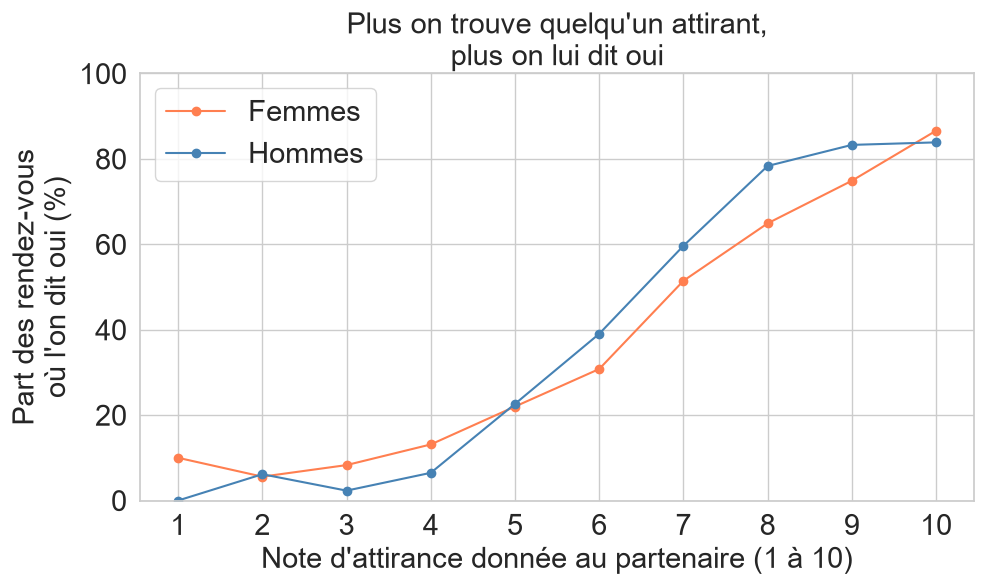

In [37]:
# Graphique 1 : la probabilité de dire oui selon la note d'attirance donnée au partenaire.
taux_oui_par_note = (
    df_propre.dropna(subset=["attr", "dec"])
    .assign(note=lambda d: d["attr"].round().clip(1, 10).astype(int))
    .groupby(["note", "gender"])["dec"]
    .mean()
    .unstack()
    * 100
)
taux_oui_par_note.columns = ["Femmes", "Hommes"]
# Taille des textes, en points : la figure est posée à 280 points de large dans le dossier de
# projet, soit à peu près 0,4 fois sa taille réelle ; à 21 points, titre, axes et légende y
# gardent 8 points au moins (et environ 15 points sur la diapositive 3 du support). Le titre et
# le nom de l'axe vertical passent donc sur deux lignes.
TAILLE_TEXTE_OUI = 21
ax = taux_oui_par_note.plot(
    kind="line",
    marker="o",
    figsize=(10, 6),
    color=["coral", "steelblue"],
    fontsize=TAILLE_TEXTE_OUI,
)
ax.set_title("Plus on trouve quelqu'un attirant,\nplus on lui dit oui", fontsize=TAILLE_TEXTE_OUI)
ax.set_xlabel("Note d'attirance donnée au partenaire (1 à 10)", fontsize=TAILLE_TEXTE_OUI)
ax.set_ylabel("Part des rendez-vous\noù l'on dit oui (%)", fontsize=TAILLE_TEXTE_OUI)
ax.set_ylim(0, 100)
ax.set_xticks(range(1, 11))
ax.legend(fontsize=TAILLE_TEXTE_OUI)
plt.tight_layout()  # garde les étiquettes agrandies dans le cadre de la figure
plt.show()

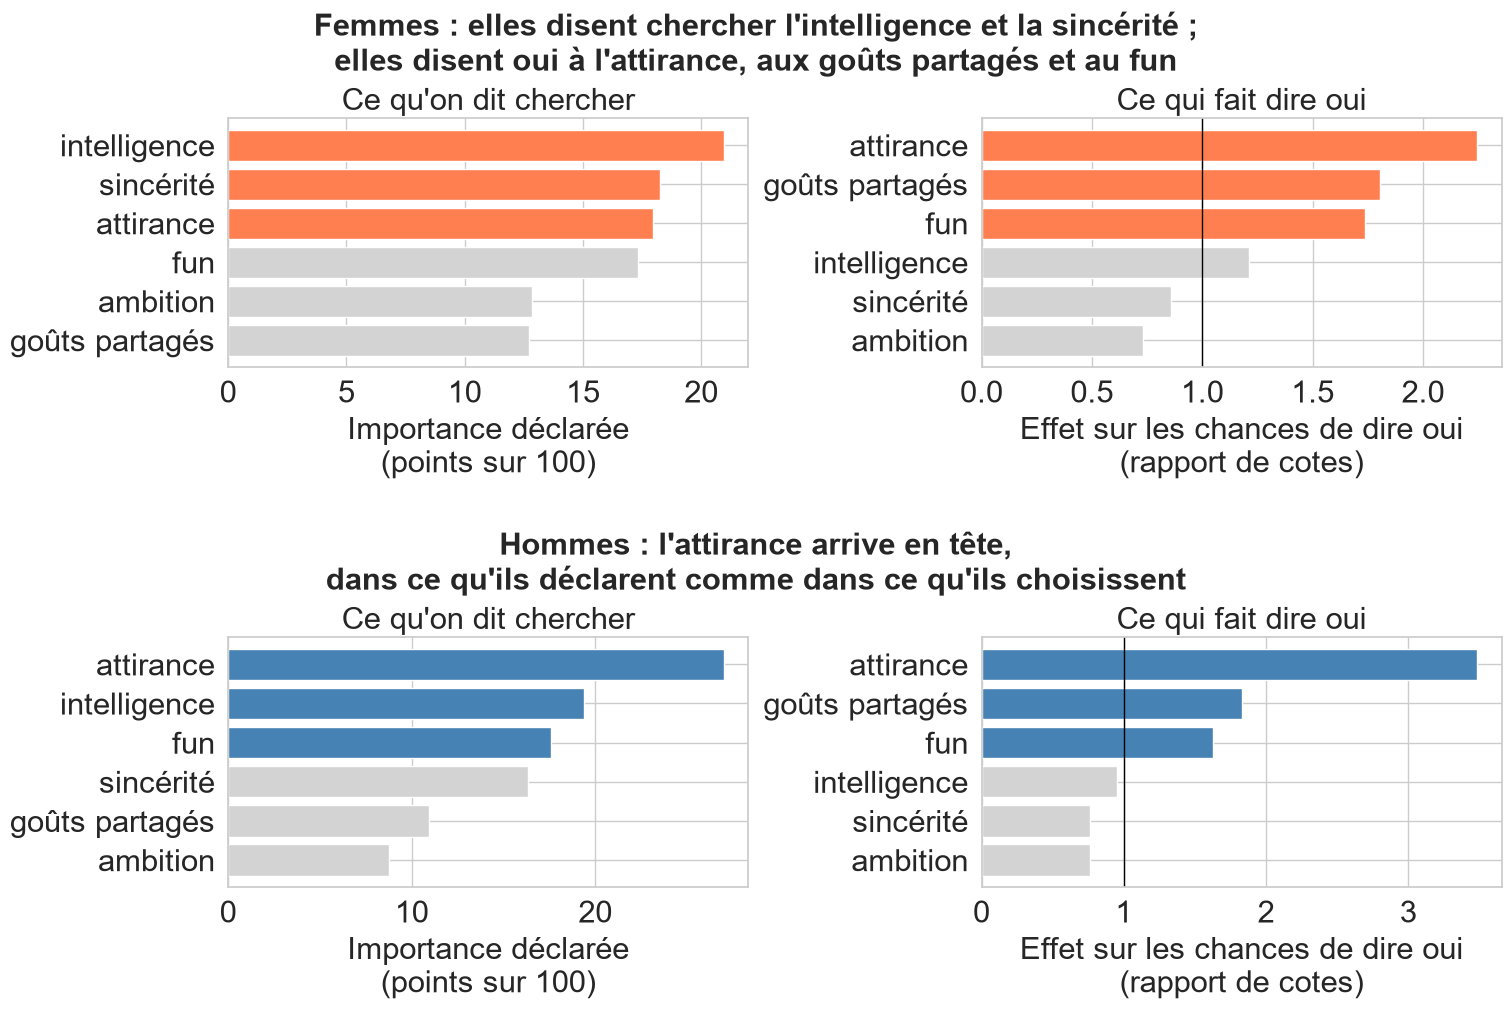

In [38]:
# Graphique 2 : ce que l'on déclare chercher, et ce qui fait réellement dire oui, sexe par sexe.
# Une ligne par sexe : à gauche, l'importance déclarée à l'inscription (points sur 100) ; à
# droite, l'effet réel d'une note plus haute d'un écart-type sur les chances de dire oui
# (rapport de cotes ; 1 = aucun effet). Les deux échelles diffèrent : on compare l'ORDRE des
# critères (barres triées, les trois premiers en couleur), pas la longueur des barres.
rapports_cotes = pd.DataFrame(
    {
        sexe: rapports_de_cotes(
            resultats_logit[sexe].params[[n + "_z" for n in notes_standard]]
        ).to_numpy()
        for sexe in ["Femmes", "Hommes"]
    },
    index=labels_notes,
)
declare = moyennes_declarees.T.copy()
declare.columns = ["Femmes", "Hommes"]
declare.index = labels_notes

titres_lignes = {
    "Femmes": "Femmes : elles disent chercher l'intelligence et la sincérité ;\n"
    "elles disent oui à l'attirance, aux goûts partagés et au fun",
    "Hommes": "Hommes : l'attirance arrive en tête,\n"
    "dans ce qu'ils déclarent comme dans ce qu'ils choisissent",
}
couleurs_sexe = {"Femmes": "coral", "Hommes": "steelblue"}
# Taille des textes, en points : la figure est posée à 400 points de large dans le dossier de
# projet, soit à peu près 0,37 fois sa taille réelle ; à 22 points, titres, noms d'axes et
# graduations y gardent 8 points au moins. Les titres et les noms d'axes longs passent donc sur
# deux lignes.
TAILLE_TEXTE_CRITERES = 22
# Une sous-figure par sexe : son titre (le message) coiffe ses deux panneaux.
fig = plt.figure(figsize=(15, 10), layout="constrained")
# subfigures(2, 1) renvoie toujours un tableau de deux sous-figures ; le cast le dit à mypy.
sous_figures = cast("np.ndarray[Any, Any]", fig.subfigures(2, 1, hspace=0.08))
for sous_figure, nom_sexe in zip(sous_figures, ["Femmes", "Hommes"], strict=True):
    sous_figure.suptitle(
        titres_lignes[nom_sexe], fontsize=TAILLE_TEXTE_CRITERES, fontweight="bold"
    )
    axes = sous_figure.subplots(1, 2)
    for panneau, (valeurs, etiquette) in enumerate(
        [
            (declare[nom_sexe], "Importance déclarée\n(points sur 100)"),
            (rapports_cotes[nom_sexe], "Effet sur les chances de dire oui\n(rapport de cotes)"),
        ]
    ):
        tri = valeurs.sort_values()  # barh : la plus grande valeur en haut
        couleurs = [
            couleurs_sexe[nom_sexe] if rang >= len(tri) - 3 else "lightgray"
            for rang in range(len(tri))
        ]
        ax = axes[panneau]
        ax.barh(tri.index, tri.to_numpy(), color=couleurs)
        ax.set_xlabel(etiquette, fontsize=TAILLE_TEXTE_CRITERES)
        ax.tick_params(labelsize=TAILLE_TEXTE_CRITERES)
        ax.locator_params(axis="x", nbins=5)  # graduations espacées : elles ne se chevauchent pas
        if panneau == 1:
            ax.axvline(1, color="black", linewidth=1)  # 1 = aucun effet
        ax.set_title(
            "Ce qu'on dit chercher" if panneau == 0 else "Ce qui fait dire oui",
            fontsize=TAILLE_TEXTE_CRITERES,
        )
plt.show()

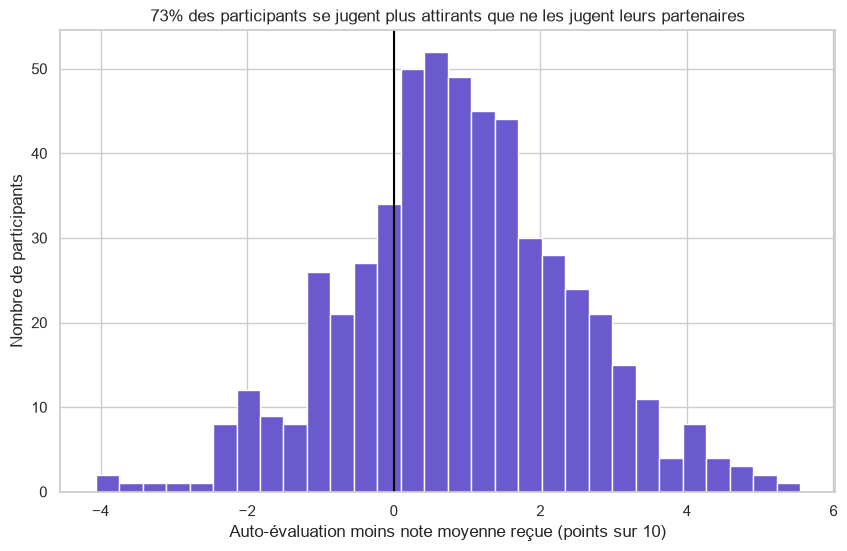

In [39]:
# Graphique 3 : l'écart entre l'image de soi et la note reçue.
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(ecarts_auto, bins=30, color="slateblue", edgecolor="white")
ax.axvline(0, color="black", linewidth=1.5)
ax.set_title(
    f"{(ecarts_auto > 0).mean():.0%} des participants se jugent plus attirants "
    "que ne les jugent leurs partenaires"
)
ax.set_xlabel("Auto-évaluation moins note moyenne reçue (points sur 10)")
ax.set_ylabel("Nombre de participants")
plt.show()

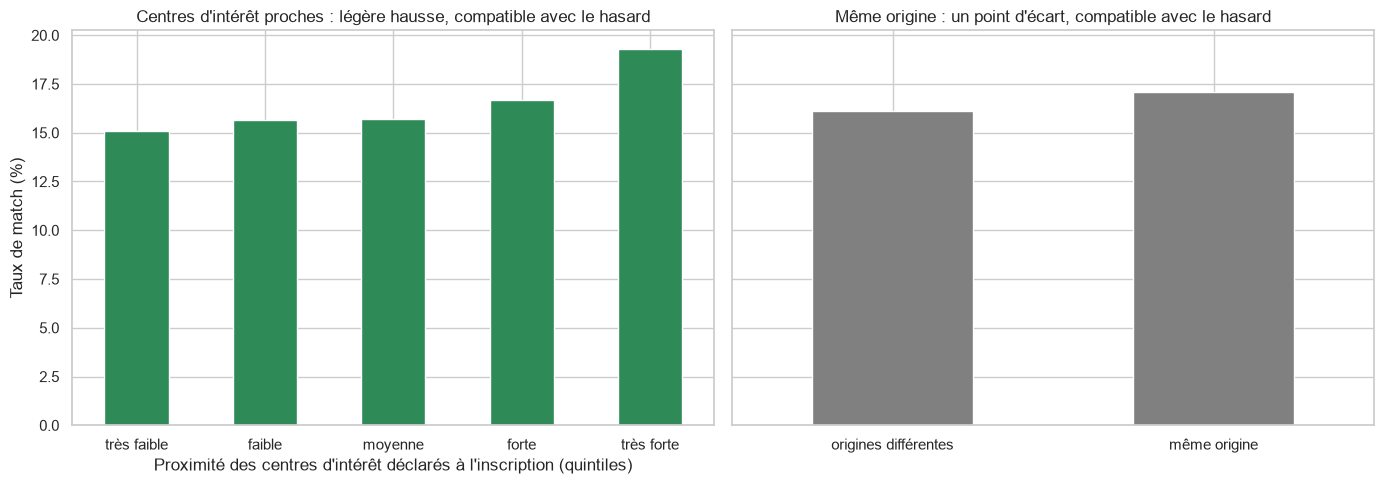

In [40]:
# Graphique 4 : proximité des centres d'intérêt déclarés et même origine : taux de match.
# Une ligne par rendez-vous (rdv), comme dans les tests (c) et (d).
quintiles = pd.qcut(
    rdv["int_corr"], q=5, labels=["très faible", "faible", "moyenne", "forte", "très forte"]
)
taux_par_quintile = rdv.groupby(quintiles, observed=True)["match"].mean() * 100
taux_par_origine = (rdv.groupby("samerace")["match"].mean() * 100).rename(
    {0: "origines différentes", 1: "même origine"}
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
taux_par_quintile.plot(kind="bar", ax=axes[0], color="seagreen")
axes[0].set_title("Centres d'intérêt proches : légère hausse, compatible avec le hasard")
axes[0].set_xlabel("Proximité des centres d'intérêt déclarés à l'inscription (quintiles)")
axes[0].set_ylabel("Taux de match (%)")
axes[0].tick_params(axis="x", rotation=0)
taux_par_origine.plot(kind="bar", ax=axes[1], color="gray")
axes[1].set_title("Même origine : un point d'écart, compatible avec le hasard")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

> **Interprétation** : les quatre graphiques résument l'étude pour un public non
> spécialiste. (1) La part de oui passe de moins de 15 % pour une note d'attirance de 4 ou moins
> à 75-87 % pour une note de 9 ou 10, chez les femmes comme chez les hommes. (2) Chez les
> femmes, ce qu'elles déclarent chercher (intelligence, sincérité) n'est pas ce qui les fait
> dire oui (attirance, goûts partagés perçus, fun) ; chez les hommes, l'attirance est en tête
> dans les deux cas. (3) Près de trois participants sur quatre se jugent plus attirants que ne
> les jugent leurs partenaires. (4) La proximité des centres d'intérêt déclarés et l'origine
> commune ne changent le taux de match que de quelques points, sans effet démontré.

## 7. Réponse à la question centrale et recommandations

**Pourquoi certains obtiennent-ils un second rendez-vous ?** Parce qu'en quatre minutes, ils
suscitent trois impressions : être trouvé **attirant**, être trouvé **drôle** (« fun ») et donner
le sentiment de **goûts partagés**. Ce sont les trois seuls critères dont l'effet positif sur
le oui est démontré pour les deux sexes, à notes égales sur les autres (section 4 c, seuil
corrigé). L'attirance pèse le plus, nettement plus chez les hommes (× 3,5 par écart-type)
que chez les femmes (× 2,2) : la différence est significative (p = 0,001). Comme un match exige deux oui, seuls 16,5 % des rendez-vous y
parviennent.

Les femmes déclarent chercher d'abord l'intelligence et la sincérité, qui ne pèsent pas, de
façon démontrée, dans leurs décisions ; les hommes déclarent l'attirance, et c'est bien elle qui
domine leurs choix. Plus largement, rien ne montre que l'importance déclarée d'un critère
guide les décisions (test d'interaction, section 4 c bis). L'origine commune, la proximité des
centres d'intérêt déclarés à l'inscription et le rang du rendez-vous n'ont pas d'effet
démontré. Enfin, la plupart des participants surestiment leur propre attirance.

**Recommandations pour l'équipe marketing de Tinder** (six, chacune reliée à un résultat)

1. **Soigner l'attirance au premier contact, sans tromperie** : encourager des photos récentes
   et variées, avec vérification du profil, puisque l'attirance est le premier moteur du oui
   (section 4 c).
2. **Faire émerger le fun et les goûts partagés dès le profil** : questions ludiques, goûts
   affichés, points communs mis en avant à l'écran. Ce sont les deux leviers qui suivent
   l'attirance, pour les deux sexes. Chez les femmes, leur poids est proche du sien (× 1,8 et
   × 1,7 par écart-type, contre × 2,2) ; chez les hommes, il est nettement inférieur (× 1,8 et
   × 1,6, contre × 3,5).
3. **Ne pas filtrer sur l'origine** : aucun effet démontré sur le match (17,1 % contre 16,1 %,
   test c), et ce serait traiter une donnée sensible (article 9 du RGPD) sans bénéfice établi.
4. **Ne pas fonder la mise en relation sur les seules préférences déclarées** : dans ces données,
   l'importance qu'une personne déclare accorder à un critère ne change pas, de façon
   démontrée, le poids de ce critère dans ses choix (section 4 c bis). Mieux vaut apprendre des
   comportements réels (likes) pour personnaliser, en gardant les préférences déclarées comme
   point de départ pour un nouvel inscrit.
5. **Aider chacun à mieux se présenter** : conseils de profil et retour agrégé (par exemple,
   les photos qui obtiennent le plus de likes), pour réduire l'écart entre l'image de soi et la
   perception des autres (73 % se surestiment, test f).
6. **Valider chaque recommandation par un test A/B** sur l'application (taux de match par
   utilisateur), car ces données décrivent des rencontres en face à face de 2002 à 2004.

**Limites de l'étude**

- Données de 2002 à 2004 : les usages de la rencontre en ligne ont beaucoup changé depuis.
- Échantillon d'étudiants d'une université américaine (âge médian 26 ans) : généralisation
  prudente à l'ensemble des utilisateurs.
- Rencontres hétérosexuelles en face à face de quatre minutes : les résultats ne se
  transposent pas directement aux échanges en ligne ni aux autres orientations.
- Corrélation n'est pas causalité : une note élevée accompagne le oui sans en être la seule
  cause ; des facteurs non mesurés (voix, contexte, « courant qui passe ») interviennent.
- Le match (deux oui le soir même) est une approximation du second rendez-vous, que les
  données ne mesurent pas directement.
- 15 à 18 % des décisions sont écartées des régressions faute d'une note complète (aucune
  imputation, pour ne pas inventer de jugements) : si ces absences ne sont pas dues au hasard,
  les coefficients peuvent en être légèrement biaisés.
- Les erreurs standard tiennent compte des décisions répétées d'un même participant et de
  celles portant sur un même partenaire, mais pas de la corrélation possible entre les deux
  décisions d'un même rendez-vous (a sur b, b sur a), qui tombent dans des groupes différents :
  pour les régressions sur les décisions, les p-valeurs peuvent rester un peu optimistes.
- Le test d'interaction (section 4 c bis) ne démontre pas d'effet des préférences déclarées ;
  cela ne prouve pas qu'il n'en existe aucun, seulement qu'il n'est pas assez fort pour être
  détecté ici.

## 8. Conformité RGPD

Ce projet manipule des données à caractère personnel, dont certaines relèvent des catégories
particulières. Ce que le RGPD exige, et ce qui est fait ici :

- **Ce sont des données personnelles (article 4.1)** : âge, études, code postal, revenus du
  quartier, objectifs de rencontre, notes données et reçues se rapportent à des personnes
  identifiables, même sans leur nom.
- **Catégories particulières (article 9)** : l'origine ethnique déclarée (`race`, `race_o`)
  et l'importance accordée à la religion (`imprelig`). Leur traitement est en principe
  interdit, sauf exception (consentement explicite, recherche scientifique avec garanties…).
- **Pseudonymisation (article 4.5)** : l'identifiant `iid` remplace le nom. Mais la
  pseudonymisation n'est pas l'anonymat (considérant 26) : en croisant âge, études, code
  postal et vague, une personne pourrait être réidentifiée. Les données restent donc soumises
  au RGPD.
- **Minimisation (article 5.1.c), appliquée et vérifiable dans le code** : les bases d'analyse
  (`df_propre`, `rdv`, `personnes`) ne reprennent ni `race`, ni `race_o`, ni `imprelig`, ni
  les données de revenus, d'études ou de code postal. La seule variable dérivée d'une donnée
  de l'article 9 est `samerace` (même origine ou non), indispensable au test (c) et réduite à
  un indicateur binaire. Les 195 colonnes d'origine ne restent que dans `df_brut`, en mémoire,
  pour la traçabilité de l'audit ; elles ne sont ni exportées ni affichées ligne à ligne.
- **Limitation des finalités (article 5.1.b)** : l'analyse vise à comprendre les mécanismes du
  choix ; aucune décision n'est prise sur une personne, et l'origine n'est utilisée que pour
  vérifier qu'elle ne change pas les chances de match (recommandation 3 : ne pas filtrer
  dessus).
- **Pas de réidentification** : les résultats sont publiés uniquement sous forme agrégée ;
  aucune ligne individuelle n'est affichée.
- **Pour un produit Tinder** : collecter l'origine ou la religion exigerait le consentement
  explicite de l'utilisateur (article 9.2.a), une information claire (articles 12 à 14) et
  l'exercice des droits d'accès, de rectification et d'effacement (articles 15 à 17) ; une
  analyse d'impact (article 35) serait requise, s'agissant de données sensibles traitées à
  grande échelle.

*Copyright © 2026 · Auteur : KinSushi · Enzo · Sovralys LLC*